# NGC 253 PN inference diagnostics — v4.0


- all diagnostic fluxes and formal uncertainties are read directly from `ADP.2025-07-06T07_52_11.876.fits`;
- aperture photometry with a 3-pixel aperture and 6–9 pixel background annulus;
- 3σ-clipped median background and propagated aperture + background-estimation uncertainty;
- line ratios retained only when both lines have S/N > 2;
- [O III] morphology from an error-weighted circular **Moffat** fit with fixed β = 2.8, fitted over 11×11 pixels;
- Moffat centroid constrained to ±1 pixel, amplitude > 0, and FWHM constrained to 1–10 pixels;
- reduced χ² retained as a morphology-quality diagnostic, not as a rejection cut;
- edge objects remain in source counts/spatial maps but are excluded from 32×32 photometry/morphology comparisons;
- fixed random visual samples of 25 recovered PNe + 25 unmatched candidates in each score bin: 0.45–0.60, 0.60–0.80, and ≥0.80.

The notebook deliberately does **not** classify unmatched detections as false positives. The purpose is to determine *why* they differ from known PNe, if they do.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.stats import sigma_clip, mad_std
from scipy.ndimage import maximum_filter
from scipy.optimize import least_squares
from scipy.stats import spearmanr
from tensorflow import keras

MODEL_PATH = "best_PN_ResUNet_focal_all_grouped_v4.9.3_4channel_snr_gated_cpuinput.keras"
FITS_PATH = "/Users/golta/Neb_det/data/NGC253_4channel.fits"
NORM_PATH = "PN_ResUNet_normalization_v4.9.3_4channel_snr_gated_cpuinput.npz"
CATALOG_PATH = "/Users/golta/Neb_det/data/PN_CAT.csv"
ORIGINAL_FITS_PATH = "/Users/golta/Neb_det/data/ADP.2025-07-06T07_52_11.876.fits"
OUTPUT_DIR = Path("/Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TILE_SIZE = 64
STRIDE = 32
BATCH_SIZE = 32
MIN_DISTANCE = 3

# Fixed diagnostic operating point agreed for this analysis.
MATCH_TOLERANCE = 2.0
MATCH_TOLERANCE_GRID = np.array([1.0, 1.5, 2.0, 2.5, 3.0, 4.0])

# Cutout / measurement settings.
DIAG_CUTOUT_SIZE = 32
EDGE_MARGIN = DIAG_CUTOUT_SIZE // 2
APERTURE_RADIUS = 3.0
BG_INNER_RADIUS = 6.0
BG_OUTER_RADIUS = 9.0
BG_CLIP_SIGMA = 3.0
RATIO_SNR_MIN = 2.0

# [O III] 5007 magnitude convention: m5007 = -2.5 log10(F5007) - 13.74
# F5007 must be in erg s^-1 cm^-2. Leave this at 1.0 when the ADP flux
# extension is already in cgs; change only if the FITS BUNIT explicitly uses
# scaled numerical units (for example 1e-20 erg s^-1 cm^-2).
M5007_ZEROPOINT = 13.74
OIII_FLUX_TO_CGS = 1e-20

# Moffat morphology settings.
MOFFAT_BETA = 2.8
MOFFAT_FIT_SIZE = 11
MOFFAT_CENTROID_MAX_SHIFT = 1.0
MOFFAT_FWHM_MIN = 1.0
MOFFAT_FWHM_MAX = 10.0

# Visual sampling.
VISUAL_N_PER_POP_PER_BIN = 25
VISUAL_SEED = 20260913
SCORE_BIN_EDGES = [0.45, 0.60, 0.80, np.inf]
SCORE_BIN_LABELS = ["0.45-0.60", "0.60-0.80", ">=0.80"]

LINE_NAMES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]

norm = np.load(NORM_PATH, allow_pickle=True)
FLUX_SCALE = float(norm["flux_scale"])
asinh_scale = norm["asinh_scale"].astype(np.float32)
CHANNEL_MEANS = norm["channel_means"].astype(np.float32)
CHANNEL_STDS = norm["channel_stds"].astype(np.float32)
SAVED_VALIDATION_THRESHOLD = float(norm["detection_threshold"])
DIAGNOSTIC_THRESHOLD = SAVED_VALIDATION_THRESHOLD

print("FLUX_SCALE:", FLUX_SCALE)
print("CHANNEL_MEANS:", CHANNEL_MEANS)
print("CHANNEL_STDS:", CHANNEL_STDS)
print("Saved validation threshold:", SAVED_VALIDATION_THRESHOLD)
print("Diagnostic inference threshold:", DIAGNOSTIC_THRESHOLD)
if not np.isclose(SAVED_VALIDATION_THRESHOLD, DIAGNOSTIC_THRESHOLD):
    print("NOTE: diagnostic threshold is intentionally fixed at 0.45 for this analysis.")

model = keras.models.load_model(MODEL_PATH, compile=False)
print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)


FLUX_SCALE: 1e+18
CHANNEL_MEANS: [0.49509016 0.47126815 0.47550353 0.47398502]
CHANNEL_STDS: [0.88668114 0.63045555 0.9024692  0.8066707 ]
Saved validation threshold: 0.45000000000000007
Diagnostic inference threshold: 0.45000000000000007


2026-10-15 10:44:12.096901: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-10-15 10:44:12.096924: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-15 10:44:12.096929: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1792053852.097192 1898524 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792053852.097249 1898524 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model input shape : (None, 64, 64, 4)
Model output shape: (None, 64, 64, 1)


In [2]:
with fits.open(FITS_PATH) as hdul:
    data = hdul[0].data

data = np.squeeze(np.asarray(data, dtype=np.float32))
print("Original FITS shape:", data.shape)

if data.ndim != 3:
    raise ValueError(f"Expected a 3D FITS array, got shape {data.shape}")

if data.shape[-1] == 4:
    image = data
elif data.shape[0] == 4:
    image = np.moveaxis(data, 0, -1)
else:
    raise ValueError(f"Could not find the 4-channel axis. FITS shape is {data.shape}")

print("Image shape used by network:", image.shape)
assert image.shape[-1] == 4

print("Expected channel order:")
for i, name in enumerate(LINE_NAMES):
    print(i, name)

Original FITS shape: (1733, 6080, 4)
Image shape used by network: (1733, 6080, 4)
Expected channel order:
0 Hbeta
1 OIII5007
2 Halpha
3 NII6584


In [3]:
def replace_nonfinite_channels(image):
    """Replace only NaN/Inf values; do not clip finite astrophysical signal."""
    clean = image.astype(np.float32, copy=True)

    for c in range(clean.shape[-1]):
        channel = clean[:, :, c]
        valid = np.isfinite(channel)

        if not np.any(valid):
            raise ValueError(f"Channel {c} contains no finite values.")

        n_invalid = int(np.sum(~valid))
        replacement = float(np.median(channel[valid]))
        channel[~valid] = replacement

        print(
            f"Channel {c}: invalid replaced={n_invalid}, "
            f"replacement median={replacement:.4e}"
        )

    return clean


# 1. Safety repair only. No sigma clipping: finite real-image values are kept.
image_clean = replace_nonfinite_channels(image)

# 2. Exactly the saved training transform.
image_scaled = image_clean * np.float32(FLUX_SCALE)

image_transformed = np.arcsinh(
    image_scaled / asinh_scale[None, None, :]
)

image_norm = (
    image_transformed - CHANNEL_MEANS[None, None, :]
) / CHANNEL_STDS[None, None, :]

image_norm = image_norm.astype(np.float32)

if not np.all(np.isfinite(image_norm)):
    raise ValueError("Normalized image still contains NaN or Inf values.")

print("\nFinal normalized image statistics:")
for c, name in enumerate(norm["line_names"]):
    x = image_norm[:, :, c]
    print(
        f"{name}: "
        f"mean={x.mean():.3f}, "
        f"std={x.std():.3f}, "
        f"min={x.min():.3f}, "
        f"max={x.max():.3f}"
    )


Channel 0: invalid replaced=2099462, replacement median=9.9090e-19
Channel 1: invalid replaced=2098866, replacement median=7.4025e-19
Channel 2: invalid replaced=2098718, replacement median=2.5497e-18
Channel 3: invalid replaced=2098612, replacement median=1.3745e-18

Final normalized image statistics:
Hbeta: mean=-0.191, std=0.416, min=-0.558, max=18.239
OIII5007: mean=-0.142, std=0.600, min=-0.748, max=28.870
Halpha: mean=-0.214, std=0.439, min=-0.527, max=12.680
NII6584: mean=-0.192, std=0.479, min=-0.588, max=10.645


In [4]:
def get_start_positions(length, tile_size, stride):
    if length <= tile_size:
        return [0]

    positions = list(range(0, length - tile_size + 1, stride))
    final_position = length - tile_size
    if positions[-1] != final_position:
        positions.append(final_position)
    return positions


def predict_full_image(model, image, tile_size=64, stride=32, batch_size=32):
    height, width, channels = image.shape
    assert channels == 4

    pad_y = max(0, tile_size - height)
    pad_x = max(0, tile_size - width)
    if pad_y > 0 or pad_x > 0:
        image_padded = np.pad(image, ((0, pad_y), (0, pad_x), (0, 0)), mode="edge")
    else:
        image_padded = image

    padded_height, padded_width, _ = image_padded.shape
    y_positions = get_start_positions(padded_height, tile_size, stride)
    x_positions = get_start_positions(padded_width, tile_size, stride)
    coordinates = [(y, x) for y in y_positions for x in x_positions]
    print("Number of tiles:", len(coordinates))

    prediction_sum = np.zeros((padded_height, padded_width), dtype=np.float32)
    weight_sum = np.zeros((padded_height, padded_width), dtype=np.float32)

    w = np.hanning(tile_size).astype(np.float32)
    weight = 0.1 + 0.9 * np.outer(w, w)

    for start in range(0, len(coordinates), batch_size):
        batch_coords = coordinates[start:start + batch_size]
        batch = np.stack([
            image_padded[y:y + tile_size, x:x + tile_size, :]
            for y, x in batch_coords
        ])
        batch_predictions = model.predict(batch, verbose=0)[..., 0]

        for (y, x), pred in zip(batch_coords, batch_predictions):
            prediction_sum[y:y + tile_size, x:x + tile_size] += pred * weight
            weight_sum[y:y + tile_size, x:x + tile_size] += weight

    full_prediction = prediction_sum / np.maximum(weight_sum, 1e-12)
    return full_prediction[:height, :width]

In [5]:
pn_heatmap = predict_full_image(model, image_norm, tile_size=TILE_SIZE, stride=STRIDE, batch_size=BATCH_SIZE)
#pn_heatmap[~valid_mask] = 0.0

print("Final heatmap shape:", pn_heatmap.shape)
print("Prediction range:", pn_heatmap.min(), pn_heatmap.max())

Number of tiles: 10206


2026-10-15 10:44:13.595904: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Final heatmap shape: (1733, 6080)
Prediction range: 0.0 0.9470467


In [6]:
def find_pn_centers(heatmap, threshold=0.30, min_distance=3):
    """Same local-maximum implementation used by the training notebook."""
    size = 2 * min_distance + 1
    local_max = heatmap == maximum_filter(
        heatmap,
        size=size,
        mode="constant",
    )
    detected = local_max & (heatmap >= threshold)

    y, x = np.where(detected)
    scores = heatmap[y, x]
    order = np.argsort(scores)[::-1]

    return np.column_stack([x[order], y[order], scores[order]])


detections = find_pn_centers(
    pn_heatmap,
    threshold=DIAGNOSTIC_THRESHOLD,
    min_distance=MIN_DISTANCE,
)

print(f"Number of PN candidates at threshold {DIAGNOSTIC_THRESHOLD:.2f}: {len(detections)}")
print("Top 10 [x, y, score]:")
print(detections[:10])


Number of PN candidates at threshold 0.45: 1248
Top 10 [x, y, score]:
[[3.00000000e+03 9.63000000e+02 9.47046697e-01]
 [5.15400000e+03 1.07500000e+03 9.23013031e-01]
 [2.94900000e+03 1.06900000e+03 9.12872076e-01]
 [5.62600000e+03 9.02000000e+02 9.09739852e-01]
 [4.34400000e+03 9.52000000e+02 9.08423245e-01]
 [3.91100000e+03 5.61000000e+02 9.07539845e-01]
 [3.72600000e+03 1.03500000e+03 9.06763077e-01]
 [3.88100000e+03 8.13000000e+02 9.01658475e-01]
 [3.91700000e+03 6.01000000e+02 8.97531390e-01]
 [1.58100000e+03 9.46000000e+02 8.96984458e-01]]


In [7]:
pn_catalog = pd.read_csv(CATALOG_PATH)

# Accept common catalogue spellings while keeping the original column untouched.
CATALOG_M5007_COLUMN = next(
    (col for col in ["m5007", "M5007", "m_5007", "M_5007"] if col in pn_catalog.columns),
    None,
)
print("Catalogue m5007 column:", CATALOG_M5007_COLUMN)
print(pn_catalog.head())
print("Number of catalogue PNe:", len(pn_catalog))

with fits.open(ORIGINAL_FITS_PATH) as hdul:
    wcs = WCS(hdul["OIII5006_FLUX"].header).celestial

# Mean projected pixel scale from the same OIII WCS used for catalogue coordinates.
# PN_CAT.csv FWHM is in arcsec; our Moffat fit is initially in pixels.
pixel_scales_deg = proj_plane_pixel_scales(wcs)
PIXEL_SCALE_ARCSEC = float(np.mean(np.abs(pixel_scales_deg)) * 3600.0)
print(f"Pixel scale from OIII WCS: {PIXEL_SCALE_ARCSEC:.5f} arcsec/pixel")

ra = pn_catalog["RAdeg"].to_numpy()
dec = pn_catalog["DEdeg"].to_numpy()
catalog_x, catalog_y = wcs.world_to_pixel_values(ra, dec)
pn_catalog["x"] = catalog_x
pn_catalog["y"] = catalog_y

print(pn_catalog[["ID", "RAdeg", "DEdeg", "x", "y"]].head())

height, width, _ = image.shape
inside_image = (
    np.isfinite(pn_catalog["x"]) & np.isfinite(pn_catalog["y"])
    & (pn_catalog["x"] >= 0) & (pn_catalog["x"] < width)
    & (pn_catalog["y"] >= 0) & (pn_catalog["y"] < height))

catalog_in_image = pn_catalog[inside_image].copy()
print(f"Catalogue PNe inside image: {len(catalog_in_image)} / {len(pn_catalog)}")

Catalogue m5007 column: m5007
   ID      RAdeg      DEdeg   FWHM  log_OIII_Hb  log_NII_Ha  log_SII_Ha  \
0   1  11.987615 -25.221952  0.956     1.871572    0.028113   -1.241971   
1   2  11.994759 -25.220211  0.923     1.776825   -0.548196   -1.497087   
2   3  12.021884 -25.194207  0.786     1.073425   -0.153119   -2.029765   
3   4  11.992403 -25.218152  1.080     1.436248   -0.857334   -0.846140   
4   5  11.990650 -25.220049  1.083     1.405052   -0.738616   -0.659834   

    m5007  OIII_SNR  OIII_BKG     HA_BKG  use_NII  use_SII  
0  24.724    95.148  4635.374   8483.608    False    False  
1  25.008    81.816  5043.334   8932.815    False    False  
2  24.709   132.907  3856.435  15246.028     True    False  
3  25.433    48.006  4647.829  12368.687    False    False  
4  25.789    37.488  5518.461  12392.201    False    False  
Number of catalogue PNe: 571
Pixel scale from OIII WCS: 0.20000 arcsec/pixel
   ID      RAdeg      DEdeg            x           y
0   1  11.987615 -25.22

In [8]:
def match_catalog_to_detections(catalog, detections, tolerance):
    """One-to-one nearest-pair catalogue recovery matching.

    The catalogue is a positive-reference set. Unmatched model detections are
    called unmatched candidates, not false positives.
    """
    catalog = catalog.copy().reset_index(drop=True)
    cat_xy = catalog[["x", "y"]].to_numpy(dtype=np.float32)
    det = np.asarray(detections, dtype=np.float32)

    matched_catalog_indices = set()
    matched_detection_indices = set()
    accepted_pairs = []

    if len(catalog) > 0 and len(det) > 0:
        det_xy = det[:, :2]
        dx = cat_xy[:, None, 0] - det_xy[None, :, 0]
        dy = cat_xy[:, None, 1] - det_xy[None, :, 1]
        distances = np.sqrt(dx**2 + dy**2)
        candidate_pairs = np.argwhere(distances <= tolerance)

        if len(candidate_pairs) > 0:
            pair_distances = distances[candidate_pairs[:, 0], candidate_pairs[:, 1]]
            for pair_index in np.argsort(pair_distances):
                cat_index, det_index = candidate_pairs[pair_index]
                cat_index, det_index = int(cat_index), int(det_index)
                if cat_index in matched_catalog_indices or det_index in matched_detection_indices:
                    continue
                matched_catalog_indices.add(cat_index)
                matched_detection_indices.add(det_index)
                accepted_pairs.append((cat_index, det_index, float(distances[cat_index, det_index])))

    matched = np.zeros(len(catalog), dtype=bool)
    matched_detection_x = np.full(len(catalog), np.nan)
    matched_detection_y = np.full(len(catalog), np.nan)
    matched_detection_score = np.full(len(catalog), np.nan)
    matched_distance = np.full(len(catalog), np.nan)
    matched_detection_index = np.full(len(catalog), -1, dtype=int)

    for cat_index, det_index, distance in accepted_pairs:
        matched[cat_index] = True
        matched_detection_x[cat_index] = det[det_index, 0]
        matched_detection_y[cat_index] = det[det_index, 1]
        matched_detection_score[cat_index] = det[det_index, 2]
        matched_distance[cat_index] = distance
        matched_detection_index[cat_index] = det_index

    catalog["detected_by_model"] = matched
    catalog["matched_x"] = matched_detection_x
    catalog["matched_y"] = matched_detection_y
    catalog["matched_score"] = matched_detection_score
    catalog["match_distance_pix"] = matched_distance
    catalog["matched_detection_index"] = matched_detection_index

    matched_catalog = catalog[catalog["detected_by_model"]].copy()
    missed_catalog = catalog[~catalog["detected_by_model"]].copy()

    unmatched_mask = np.ones(len(det), dtype=bool)
    if matched_detection_indices:
        unmatched_mask[list(matched_detection_indices)] = False
    unmatched_detections = det[unmatched_mask].copy()

    return matched_catalog, missed_catalog, unmatched_detections


# Keep the radius sweep as a localization diagnostic, but use 2 pixels below.
recovery_rows = []
for tolerance in MATCH_TOLERANCE_GRID:
    matched_tmp, missed_tmp, unmatched_tmp = match_catalog_to_detections(
        catalog_in_image, detections, float(tolerance)
    )
    recovery_rows.append({
        "tolerance_pix": float(tolerance),
        "n_catalog_matched": len(matched_tmp),
        "n_catalog_missed": len(missed_tmp),
        "catalog_completeness": len(matched_tmp) / len(catalog_in_image) if len(catalog_in_image) else np.nan,
        "n_unmatched_candidates": len(unmatched_tmp),
    })
recovery_sweep = pd.DataFrame(recovery_rows)
display(recovery_sweep)

matched_catalog, missed_catalog, unmatched_detections = match_catalog_to_detections(
    catalog_in_image, detections, MATCH_TOLERANCE
)
completeness = len(matched_catalog) / len(catalog_in_image) if len(catalog_in_image) else np.nan

print("\nFIXED DIAGNOSTIC OPERATING POINT")
print("================================")
print(f"Threshold                 : {DIAGNOSTIC_THRESHOLD:.2f}")
print(f"Matching radius           : {MATCH_TOLERANCE:.1f} pix")
print(f"Total detections          : {len(detections)}")
print(f"Catalogue PNe in image    : {len(catalog_in_image)}")
print(f"Recovered catalogue PNe   : {len(matched_catalog)}")
print(f"Missed catalogue PNe      : {len(missed_catalog)}")
print(f"Catalogue completeness    : {100*completeness:.1f}%")
print(f"Unmatched candidates      : {len(unmatched_detections)}")


,tolerance_pix,n_catalog_matched,n_catalog_missed,catalog_completeness,n_unmatched_candidates
0,1.0,484,87,0.847636,764
1,1.5,517,54,0.905429,731
2,2.0,518,53,0.907180,730
3,2.5,518,53,0.907180,730
4,3.0,518,53,0.907180,730
5,4.0,518,53,0.907180,730



FIXED DIAGNOSTIC OPERATING POINT
Threshold                 : 0.45
Matching radius           : 2.0 pix
Total detections          : 1248
Catalogue PNe in image    : 571
Recovered catalogue PNe   : 518
Missed catalogue PNe      : 53
Catalogue completeness    : 90.7%
Unmatched candidates      : 730


## Load diagnostic line maps and error maps from the original ADP FITS

The network input remains exactly as above. For the diagnostic measurements below, both line fluxes and formal uncertainties are read directly from the original MUSE product.

In [9]:
with fits.open(ORIGINAL_FITS_PATH) as hdul:
    oiii_bunit = hdul["OIII5006_FLUX"].header.get("BUNIT", "<missing>")
    hb_flux = np.squeeze(np.asarray(hdul["HB4861_FLUX"].data, dtype=np.float64))
    oiii_flux = np.squeeze(np.asarray(hdul["OIII5006_FLUX"].data, dtype=np.float64))
    ha_flux = np.squeeze(np.asarray(hdul["HA6562_FLUX"].data, dtype=np.float64))
    nii_flux = np.squeeze(np.asarray(hdul["NII6583_FLUX"].data, dtype=np.float64))

    hb_err = np.squeeze(np.asarray(hdul["HB4861_FLUX_ERR"].data, dtype=np.float64))
    oiii_err = np.squeeze(np.asarray(hdul["OIII5006_FLUX_ERR"].data, dtype=np.float64))
    ha_err = np.squeeze(np.asarray(hdul["HA6562_FLUX_ERR"].data, dtype=np.float64))
    nii_err = np.squeeze(np.asarray(hdul["NII6583_FLUX_ERR"].data, dtype=np.float64))

print(f"OIII5006_FLUX BUNIT: {oiii_bunit}")
print(f"OIII flux-to-cgs scale used for m5007: {OIII_FLUX_TO_CGS:g}")

flux_maps = {
    "hb": hb_flux,
    "oiii": oiii_flux,
    "ha": ha_flux,
    "nii": nii_flux,
}
error_maps = {
    "hb": hb_err,
    "oiii": oiii_err,
    "ha": ha_err,
    "nii": nii_err,
}

expected_shape = pn_heatmap.shape
for name, arr in {**flux_maps, **{f"{k}_err": v for k, v in error_maps.items()}}.items():
    if arr.ndim != 2:
        raise ValueError(f"{name} must be 2D after squeeze; got shape {arr.shape}")
    if arr.shape != expected_shape:
        raise ValueError(f"{name} shape {arr.shape} does not match heatmap shape {expected_shape}")

# Sanity-check that the diagnostic ADP flux maps have the same orientation/order
# as the packed four-channel image used for inference.
packed_to_diag = [hb_flux, oiii_flux, ha_flux, nii_flux]
for channel_index, (channel_name, diag_map) in enumerate(zip(LINE_NAMES, packed_to_diag)):
    packed = image[..., channel_index].astype(float)
    valid = np.isfinite(packed) & np.isfinite(diag_map)
    if valid.sum() > 100:
        # Use at most ~100k pixels for a cheap alignment correlation check.
        flat_idx = np.flatnonzero(valid)
        if len(flat_idx) > 100000:
            step = max(1, len(flat_idx) // 100000)
            flat_idx = flat_idx[::step][:100000]
        corr = np.corrcoef(packed.ravel()[flat_idx], diag_map.ravel()[flat_idx])[0, 1]
        print(f"{channel_name}: packed-vs-ADP correlation = {corr:.6f}")
        if not np.isfinite(corr) or corr < 0.95:
            print(f"WARNING: {channel_name} alignment/value correlation is unexpectedly low.")

print("Diagnostic FITS maps loaded and shape-aligned with heatmap:", expected_shape)


OIII5006_FLUX BUNIT: <missing>
OIII flux-to-cgs scale used for m5007: 1e-20
Hbeta: packed-vs-ADP correlation = 1.000000
OIII5007: packed-vs-ADP correlation = 1.000000
Halpha: packed-vs-ADP correlation = 1.000000
NII6584: packed-vs-ADP correlation = 1.000000
Diagnostic FITS maps loaded and shape-aligned with heatmap: (1733, 6080)


## Build the three diagnostic populations

In [10]:
def max_heatmap_within_radius(heatmap, x, y, radius=3.0):
    """Maximum heatmap value within a circular radius around (x, y)."""
    h, w = heatmap.shape
    x0 = max(0, int(np.floor(x - radius)))
    x1 = min(w, int(np.ceil(x + radius)) + 1)
    y0 = max(0, int(np.floor(y - radius)))
    y1 = min(h, int(np.ceil(y + radius)) + 1)
    yy, xx = np.mgrid[y0:y1, x0:x1]
    mask = (xx - x)**2 + (yy - y)**2 <= radius**2
    vals = heatmap[y0:y1, x0:x1][mask]
    return float(np.nanmax(vals)) if vals.size else np.nan


def is_edge_object(x, y, width, height, margin=EDGE_MARGIN):
    """Flag positions that cannot support a full centered 32x32 cutout."""
    xr, yr = int(round(x)), int(round(y))
    return (xr < margin) or (yr < margin) or (xr > width - margin) or (yr > height - margin)


height, width = pn_heatmap.shape
rows = []

# Recovered catalogue PNe: center all measurements on the matched network peak.
for _, r in matched_catalog.iterrows():
    rows.append({
        "population": "Recovered catalogue PN",
        "object_id": f"PN_{r['ID']}" if "ID" in r.index else "catalogue_recovered",
        "catalog_id": r["ID"] if "ID" in r.index else np.nan,
        "center_x": float(r["matched_x"]),
        "center_y": float(r["matched_y"]),
        "catalog_x": float(r["x"]),
        "catalog_y": float(r["y"]),
        "network_score": float(r["matched_score"]),
        "match_distance_pix": float(r["match_distance_pix"]),
        "catalog_oiii_snr": float(r["OIII_SNR"]) if "OIII_SNR" in r.index else np.nan,
        "catalog_fwhm_arcsec": float(r["FWHM"]) if "FWHM" in r.index else np.nan,
        "catalog_m5007": float(r[CATALOG_M5007_COLUMN]) if CATALOG_M5007_COLUMN is not None else np.nan,
    })

# Missed catalogue PNe: center on catalogue coordinate and record local max score within 3 pix.
for _, r in missed_catalog.iterrows():
    score3 = max_heatmap_within_radius(pn_heatmap, float(r["x"]), float(r["y"]), radius=3.0)
    rows.append({
        "population": "Missed catalogue PN",
        "object_id": f"PN_{r['ID']}" if "ID" in r.index else "catalogue_missed",
        "catalog_id": r["ID"] if "ID" in r.index else np.nan,
        "center_x": float(r["x"]),
        "center_y": float(r["y"]),
        "catalog_x": float(r["x"]),
        "catalog_y": float(r["y"]),
        "network_score": score3,
        "match_distance_pix": np.nan,
        "catalog_oiii_snr": float(r["OIII_SNR"]) if "OIII_SNR" in r.index else np.nan,
        "catalog_fwhm_arcsec": float(r["FWHM"]) if "FWHM" in r.index else np.nan,
        "catalog_m5007": float(r[CATALOG_M5007_COLUMN]) if CATALOG_M5007_COLUMN is not None else np.nan,
    })

# Unmatched network candidates.
for i, (x, y, score) in enumerate(unmatched_detections):
    rows.append({
        "population": "Unmatched candidate",
        "object_id": f"unmatched_{i:05d}",
        "catalog_id": np.nan,
        "center_x": float(x),
        "center_y": float(y),
        "catalog_x": np.nan,
        "catalog_y": np.nan,
        "network_score": float(score),
        "match_distance_pix": np.nan,
        "catalog_oiii_snr": np.nan,
        "catalog_fwhm_arcsec": np.nan,
        "catalog_m5007": np.nan,
    })

objects = pd.DataFrame(rows)
objects["edge_object"] = [
    is_edge_object(x, y, width, height)
    for x, y in zip(objects["center_x"], objects["center_y"])
]

objects["score_bin"] = pd.cut(
    objects["network_score"],
    bins=[-np.inf, 0.45, 0.60, 0.80, np.inf],
    labels=["<0.45", "0.45-0.60", "0.60-0.80", ">=0.80"],
    right=False,
)

print(objects.groupby("population").size())
print("\nEdge counts:")
display(objects.groupby("population")["edge_object"].agg(["sum", "count"]))
print("\nScore bins:")
display(pd.crosstab(objects["population"], objects["score_bin"], dropna=False))


population
Missed catalogue PN        53
Recovered catalogue PN    518
Unmatched candidate       730
dtype: int64

Edge counts:


,sum,count
population,,
Missed catalogue PN,0,53
Recovered catalogue PN,0,518
Unmatched candidate,1,730



Score bins:


score_bin,<0.45,0.45-0.60,0.60-0.80,>=0.80
population,,,,
Missed catalogue PN,51,0,2,0
Recovered catalogue PN,0,111,337,70
Unmatched candidate,0,423,280,27


## Measurement functions

Formal aperture-flux uncertainty includes both source-aperture pixel errors and uncertainty in the locally estimated background. Because the adopted background estimator is a median, the error-map estimate of the median uncertainty uses the standard Gaussian factor 1.2533 relative to the mean uncertainty. The observed annulus scatter is stored separately and is **not** folded into the formal detector-noise error.

In [11]:
MEDIAN_STD_FACTOR = 1.2533141373155


def m5007_from_flux(flux_cgs, flux_err_cgs=np.nan):
    """Return Jacoby m5007 and its propagated 1-sigma error.

    m5007 = -2.5 log10(F5007) - 13.74, with F5007 in erg s^-1 cm^-2.
    Non-positive or non-finite flux has no physical logarithmic magnitude.
    """
    if not np.isfinite(flux_cgs) or flux_cgs <= 0:
        return np.nan, np.nan
    mag = -2.5 * np.log10(flux_cgs) - M5007_ZEROPOINT
    if np.isfinite(flux_err_cgs) and flux_err_cgs > 0:
        mag_err = (2.5 / np.log(10.0)) * flux_err_cgs / flux_cgs
    else:
        mag_err = np.nan
    return float(mag), float(mag_err)


def moffat_encircled_fraction(radius_pix, fwhm_pix, beta=MOFFAT_BETA):
    """Continuous circular-Moffat encircled-flux fraction within radius."""
    if not np.isfinite(radius_pix) or not np.isfinite(fwhm_pix) or radius_pix <= 0 or fwhm_pix <= 0 or beta <= 1:
        return np.nan
    alpha = moffat_alpha_from_fwhm(fwhm_pix, beta=beta)
    frac = 1.0 - (1.0 + (radius_pix / alpha)**2)**(1.0 - beta)
    return float(frac) if 0 < frac <= 1 else np.nan



def aperture_photometry_one_line(flux, err, x, y):
    """3-pixel aperture photometry with a 6-9 pixel clipped-median annulus."""
    h, w = flux.shape
    rmax = BG_OUTER_RADIUS
    x0 = max(0, int(np.floor(x - rmax - 1)))
    x1 = min(w, int(np.ceil(x + rmax + 1)) + 1)
    y0 = max(0, int(np.floor(y - rmax - 1)))
    y1 = min(h, int(np.ceil(y + rmax + 1)) + 1)

    f = flux[y0:y1, x0:x1]
    e = err[y0:y1, x0:x1]
    yy, xx = np.mgrid[y0:y1, x0:x1]
    rr = np.sqrt((xx - x)**2 + (yy - y)**2)

    ap_geom = rr <= APERTURE_RADIUS
    bg_geom = (rr >= BG_INNER_RADIUS) & (rr < BG_OUTER_RADIUS)

    ap_valid = ap_geom & np.isfinite(f) & np.isfinite(e) & (e > 0)
    bg_valid = bg_geom & np.isfinite(f) & np.isfinite(e) & (e > 0)

    if ap_valid.sum() < 3 or bg_valid.sum() < 10:
        return {
            "flux": np.nan, "flux_err": np.nan, "snr": np.nan,
            "background": np.nan, "background_scatter": np.nan,
            "n_ap": int(ap_valid.sum()), "n_bg": int(bg_valid.sum()),
        }

    bg_values = f[bg_valid]
    bg_errors = e[bg_valid]
    clipped = sigma_clip(
        bg_values,
        sigma=BG_CLIP_SIGMA,
        maxiters=5,
        cenfunc="median",
        stdfunc="mad_std",
        masked=True,
    )
    keep = ~np.ma.getmaskarray(clipped)
    if keep.sum() < 5:
        return {
            "flux": np.nan, "flux_err": np.nan, "snr": np.nan,
            "background": np.nan, "background_scatter": np.nan,
            "n_ap": int(ap_valid.sum()), "n_bg": int(keep.sum()),
        }

    bg_values = bg_values[keep]
    bg_errors = bg_errors[keep]
    background = float(np.median(bg_values))
    background_scatter = float(mad_std(bg_values, ignore_nan=True))

    # Approximate formal uncertainty of a median under Gaussian noise.
    background_err = MEDIAN_STD_FACTOR * np.sqrt(np.sum(bg_errors**2)) / len(bg_errors)

    ap_values = f[ap_valid]
    ap_errors = e[ap_valid]
    n_ap = int(ap_valid.sum())
    source_flux = float(np.sum(ap_values - background))
    source_flux_err = float(np.sqrt(np.sum(ap_errors**2) + (n_ap * background_err)**2))
    snr = source_flux / source_flux_err if source_flux_err > 0 else np.nan

    return {
        "flux": source_flux,
        "flux_err": source_flux_err,
        "snr": float(snr),
        "background": background,
        "background_scatter": background_scatter,
        "n_ap": n_ap,
        "n_bg": int(len(bg_values)),
    }


def moffat_alpha_from_fwhm(fwhm, beta=MOFFAT_BETA):
    return fwhm / (2.0 * np.sqrt(2.0**(1.0 / beta) - 1.0))


def moffat_fwhm_from_alpha(alpha, beta=MOFFAT_BETA):
    return 2.0 * alpha * np.sqrt(2.0**(1.0 / beta) - 1.0)


def fit_fixed_beta_moffat(oiii, oiii_error, x, y):
    """Error-weighted circular Moffat + constant background fit.

    beta is fixed at 2.8. The centroid can move at most +/-1 pixel from the
    nominal position. FWHM is constrained to 1-10 pixels.
    """
    half = MOFFAT_FIT_SIZE // 2
    cx, cy = int(round(x)), int(round(y))
    x0, x1 = cx - half, cx + half + 1
    y0, y1 = cy - half, cy + half + 1

    if x0 < 0 or y0 < 0 or x1 > oiii.shape[1] or y1 > oiii.shape[0]:
        return {"moffat_success": False, "moffat_fwhm_pix": np.nan,
                "moffat_reduced_chi2": np.nan, "moffat_x": np.nan, "moffat_y": np.nan}

    z = oiii[y0:y1, x0:x1]
    s = oiii_error[y0:y1, x0:x1]
    yy, xx = np.mgrid[y0:y1, x0:x1]
    valid = np.isfinite(z) & np.isfinite(s) & (s > 0)

    if valid.sum() < 20:
        return {"moffat_success": False, "moffat_fwhm_pix": np.nan,
                "moffat_reduced_chi2": np.nan, "moffat_x": np.nan, "moffat_y": np.nan}

    xv, yv, zv, sv = xx[valid], yy[valid], z[valid], s[valid]
    b0 = float(np.median(zv))
    a0 = float(max(np.max(zv) - b0, np.std(zv), np.finfo(float).eps))
    alpha0 = moffat_alpha_from_fwhm(4.0)
    alpha_min = moffat_alpha_from_fwhm(MOFFAT_FWHM_MIN)
    alpha_max = moffat_alpha_from_fwhm(MOFFAT_FWHM_MAX)

    # Parameters: amplitude, x0, y0, alpha, constant background.
    p0 = np.array([a0, x, y, np.clip(alpha0, alpha_min, alpha_max), b0], dtype=float)
    lower = np.array([
        np.finfo(float).eps,
        x - MOFFAT_CENTROID_MAX_SHIFT,
        y - MOFFAT_CENTROID_MAX_SHIFT,
        alpha_min,
        -np.inf,
    ])
    upper = np.array([
        np.inf,
        x + MOFFAT_CENTROID_MAX_SHIFT,
        y + MOFFAT_CENTROID_MAX_SHIFT,
        alpha_max,
        np.inf,
    ])

    def residuals(p):
        amp, xfit, yfit, alpha, background = p
        rr2 = (xv - xfit)**2 + (yv - yfit)**2
        model = amp * (1.0 + rr2 / alpha**2)**(-MOFFAT_BETA) + background
        return (zv - model) / sv

    try:
        result = least_squares(
            residuals,
            p0,
            bounds=(lower, upper),
            max_nfev=300,
        )
    except Exception:
        return {"moffat_success": False, "moffat_fwhm_pix": np.nan,
                "moffat_reduced_chi2": np.nan, "moffat_x": np.nan, "moffat_y": np.nan}

    amp, xfit, yfit, alpha, background = result.x
    fwhm = float(moffat_fwhm_from_alpha(alpha))
    dof = int(valid.sum()) - len(result.x)
    chi2 = float(np.sum(residuals(result.x)**2))
    reduced_chi2 = chi2 / dof if dof > 0 else np.nan

    physically_valid = (
        result.success
        and amp > 0
        and MOFFAT_FWHM_MIN <= fwhm <= MOFFAT_FWHM_MAX
        and abs(xfit - x) <= MOFFAT_CENTROID_MAX_SHIFT + 1e-6
        and abs(yfit - y) <= MOFFAT_CENTROID_MAX_SHIFT + 1e-6
    )

    return {
        "moffat_success": bool(physically_valid),
        "moffat_fwhm_pix": fwhm if physically_valid else np.nan,
        "moffat_reduced_chi2": reduced_chi2 if physically_valid else np.nan,
        "moffat_x": float(xfit) if physically_valid else np.nan,
        "moffat_y": float(yfit) if physically_valid else np.nan,
        "moffat_amplitude": float(amp) if physically_valid else np.nan,
        "moffat_background": float(background) if physically_valid else np.nan,
    }


In [12]:
def safe_ratio(num_flux, num_snr, den_flux, den_snr, numerator_name="line"):
    """Return (ratio, status).

    Ratios are reported only when both lines are positive and have S/N > RATIO_SNR_MIN.
    The status string is retained so visual panels can explain why a value is unavailable.
    """
    vals = [num_flux, num_snr, den_flux, den_snr]
    if not all(np.isfinite(v) for v in vals):
        return np.nan, "invalid measurement"
    if den_flux <= 0:
        return np.nan, "OIII flux <= 0"
    if num_flux <= 0:
        return np.nan, f"{numerator_name} flux <= 0"
    if den_snr <= RATIO_SNR_MIN:
        return np.nan, f"OIII S/N <= {RATIO_SNR_MIN:g}"
    if num_snr <= RATIO_SNR_MIN:
        return np.nan, f"{numerator_name} S/N <= {RATIO_SNR_MIN:g}"
    return float(num_flux / den_flux), "ok"


measurement_rows = []
line_order = ["hb", "oiii", "ha", "nii"]

for i, obj in objects.iterrows():
    rec = obj.to_dict()

    # Edge objects stay in counts/spatial maps but are excluded from cutout-based measurements.
    if bool(obj["edge_object"]):
        for line in line_order:
            for suffix in ["flux", "flux_err", "snr", "bkg", "bkg_scatter", "n_ap", "n_bg"]:
                rec[f"{line}_{suffix}"] = np.nan
        rec.update({
            "hb_over_oiii": np.nan,
            "ha_over_oiii": np.nan,
            "nii_over_oiii": np.nan,
            "hb_over_oiii_status": "edge object",
            "ha_over_oiii_status": "edge object",
            "nii_over_oiii_status": "edge object",
            "moffat_success": False,
            "moffat_fwhm_pix": np.nan,
            "moffat_reduced_chi2": np.nan,
            "moffat_x": np.nan,
            "moffat_y": np.nan,
            "moffat_amplitude": np.nan,
            "moffat_background": np.nan,
            "m5007_aperture": np.nan,
            "m5007_aperture_err": np.nan,
            "m5007_moffat_corrected": np.nan,
            "m5007_moffat_corrected_err": np.nan,
            "m5007_aperture_fraction": np.nan,
        })
        measurement_rows.append(rec)
        continue

    x, y = float(obj["center_x"]), float(obj["center_y"])
    phot = {}
    for line in line_order:
        m = aperture_photometry_one_line(flux_maps[line], error_maps[line], x, y)
        phot[line] = m
        rec[f"{line}_flux"] = m["flux"]
        rec[f"{line}_flux_err"] = m["flux_err"]
        rec[f"{line}_snr"] = m["snr"]
        rec[f"{line}_bkg"] = m["background"]
        rec[f"{line}_bkg_scatter"] = m["background_scatter"]
        rec[f"{line}_n_ap"] = m["n_ap"]
        rec[f"{line}_n_bg"] = m["n_bg"]

    rec["hb_over_oiii"], rec["hb_over_oiii_status"] = safe_ratio(
        phot["hb"]["flux"], phot["hb"]["snr"], phot["oiii"]["flux"], phot["oiii"]["snr"], "Hb"
    )
    rec["ha_over_oiii"], rec["ha_over_oiii_status"] = safe_ratio(
        phot["ha"]["flux"], phot["ha"]["snr"], phot["oiii"]["flux"], phot["oiii"]["snr"], "Ha"
    )
    rec["nii_over_oiii"], rec["nii_over_oiii_status"] = safe_ratio(
        phot["nii"]["flux"], phot["nii"]["snr"], phot["oiii"]["flux"], phot["oiii"]["snr"], "NII"
    )

    rec.update(fit_fixed_beta_moffat(oiii_flux, oiii_err, x, y))

    # Our observed m5007 from the same background-subtracted 3-pixel OIII aperture.
    # This quantity is available for any positive OIII aperture flux and is the
    # fairest population-level comparison because every source is measured identically.
    f5007_cgs = phot["oiii"]["flux"] * OIII_FLUX_TO_CGS
    f5007_err_cgs = phot["oiii"]["flux_err"] * OIII_FLUX_TO_CGS
    rec["m5007_aperture"], rec["m5007_aperture_err"] = m5007_from_flux(
        f5007_cgs, f5007_err_cgs
    )

    # Optional point-source aperture correction using the fitted fixed-beta Moffat.
    # This is useful for catalogue comparison because a 3-pixel aperture misses
    # some PSF wings. It is kept separate from the raw aperture magnitude.
    rec["m5007_moffat_corrected"] = np.nan
    rec["m5007_moffat_corrected_err"] = np.nan
    rec["m5007_aperture_fraction"] = np.nan
    if rec.get("moffat_success", False) and np.isfinite(rec.get("moffat_fwhm_pix", np.nan)):
        frac = moffat_encircled_fraction(
            APERTURE_RADIUS, rec["moffat_fwhm_pix"], beta=MOFFAT_BETA
        )
        rec["m5007_aperture_fraction"] = frac
        if np.isfinite(frac) and frac > 0 and np.isfinite(f5007_cgs) and f5007_cgs > 0:
            rec["m5007_moffat_corrected"], rec["m5007_moffat_corrected_err"] = m5007_from_flux(
                f5007_cgs / frac, f5007_err_cgs / frac
            )

    measurement_rows.append(rec)

    if (i + 1) % 500 == 0 or (i + 1) == len(objects):
        print(f"Measured {i + 1} / {len(objects)} objects")


diagnostic_table = pd.DataFrame(measurement_rows)

# Put our fitted FWHM into the same angular unit as the catalogue.
diagnostic_table["moffat_fwhm_arcsec"] = diagnostic_table["moffat_fwhm_pix"] * PIXEL_SCALE_ARCSEC

# Direct catalogue-vs-our-measurement comparison columns (catalogue objects only).
valid_cat_snr = (
    np.isfinite(diagnostic_table["catalog_oiii_snr"])
    & np.isfinite(diagnostic_table["oiii_snr"])
    & (diagnostic_table["catalog_oiii_snr"] > 0)
)
diagnostic_table["oiii_snr_ours_over_catalog"] = np.nan
diagnostic_table.loc[valid_cat_snr, "oiii_snr_ours_over_catalog"] = (
    diagnostic_table.loc[valid_cat_snr, "oiii_snr"]
    / diagnostic_table.loc[valid_cat_snr, "catalog_oiii_snr"]
)

valid_cat_fwhm = (
    np.isfinite(diagnostic_table["catalog_fwhm_arcsec"])
    & np.isfinite(diagnostic_table["moffat_fwhm_arcsec"])
    & (diagnostic_table["catalog_fwhm_arcsec"] > 0)
)
diagnostic_table["fwhm_ours_over_catalog"] = np.nan
diagnostic_table.loc[valid_cat_fwhm, "fwhm_ours_over_catalog"] = (
    diagnostic_table.loc[valid_cat_fwhm, "moffat_fwhm_arcsec"]
    / diagnostic_table.loc[valid_cat_fwhm, "catalog_fwhm_arcsec"]
)

# Catalogue-vs-our m5007 residuals.
for ours_col, out_col in [
    ("m5007_aperture", "m5007_aperture_minus_catalog"),
    ("m5007_moffat_corrected", "m5007_corrected_minus_catalog"),
]:
    valid = np.isfinite(diagnostic_table["catalog_m5007"]) & np.isfinite(diagnostic_table[ours_col])
    diagnostic_table[out_col] = np.nan
    diagnostic_table.loc[valid, out_col] = (
        diagnostic_table.loc[valid, ours_col] - diagnostic_table.loc[valid, "catalog_m5007"]
    )

diagnostic_table.to_csv(OUTPUT_DIR / "diagnostic_source_measurements_v4.2.csv", index=False)
print("Saved:", OUTPUT_DIR / "diagnostic_source_measurements_v4.2.csv")

print("\nMoffat fit success by population (non-edge objects):")
fit_summary = (
    diagnostic_table.loc[~diagnostic_table["edge_object"]]
    .groupby("population")["moffat_success"]
    .agg(["sum", "count", "mean"])
)
display(fit_summary)


Measured 500 / 1301 objects
Measured 1000 / 1301 objects
Measured 1301 / 1301 objects
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/diagnostic_source_measurements_v4.2.csv

Moffat fit success by population (non-edge objects):


,sum,count,mean
population,,,
Missed catalogue PN,53,53,1.000000
Recovered catalogue PN,518,518,1.000000
Unmatched candidate,728,729,0.998628


## Fixed score-stratified visual sample

In [13]:
visual_pool = diagnostic_table[
    diagnostic_table["population"].isin(["Recovered catalogue PN", "Unmatched candidate"])
    & (~diagnostic_table["edge_object"])
    & (diagnostic_table["network_score"] >= DIAGNOSTIC_THRESHOLD)
].copy()

visual_pool["visual_score_bin"] = pd.cut(
    visual_pool["network_score"],
    bins=SCORE_BIN_EDGES,
    labels=SCORE_BIN_LABELS,
    right=False,
    include_lowest=True,
)

sample_parts = []
for b_idx, score_bin in enumerate(SCORE_BIN_LABELS):
    for p_idx, population in enumerate(["Recovered catalogue PN", "Unmatched candidate"]):
        subset = visual_pool[
            (visual_pool["visual_score_bin"] == score_bin)
            & (visual_pool["population"] == population)
        ]
        n = min(VISUAL_N_PER_POP_PER_BIN, len(subset))
        if n > 0:
            sample_parts.append(
                subset.sample(n=n, replace=False, random_state=VISUAL_SEED + 100*b_idx + p_idx)
            )

visual_sample = pd.concat(sample_parts, ignore_index=True) if sample_parts else pd.DataFrame()
visual_sample.to_csv(OUTPUT_DIR / "visual_sample_v4.2.csv", index=False)

display(pd.crosstab(visual_sample["population"], visual_sample["visual_score_bin"]))
print("Saved:", OUTPUT_DIR / "visual_sample_v4.2.csv")


visual_score_bin,0.45-0.60,0.60-0.80,>=0.80
population,,,
Recovered catalogue PN,25,25,25
Unmatched candidate,25,25,25


Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/visual_sample_v4.2.csv


In [14]:
DISPLAY_MAPS = {
    "Hbeta": hb_flux,
    "OIII5007": oiii_flux,
    "Halpha": ha_flux,
    "NII6583": nii_flux,
    "PN heatmap": pn_heatmap,
}


def extract_centered_cutout(arr, x, y, size=DIAG_CUTOUT_SIZE):
    half = size // 2
    cx, cy = int(round(x)), int(round(y))
    x0, y0 = cx - half, cy - half
    x1, y1 = x0 + size, y0 + size
    if x0 < 0 or y0 < 0 or x1 > arr.shape[1] or y1 > arr.shape[0]:
        return None, None
    return arr[y0:y1, x0:x1], (x0, y0)


def robust_limits(values, lo=5, hi=99):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0.0, 1.0
    vmin, vmax = np.percentile(values, [lo, hi])
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmax <= vmin:
        center = float(np.nanmedian(values)) if values.size else 0.0
        scale = float(np.nanstd(values)) if values.size else 1.0
        scale = scale if np.isfinite(scale) and scale > 0 else 1.0
        return center - scale, center + scale
    return float(vmin), float(vmax)


def common_scales_for_sample(sample):
    scales = {}
    for name, arr in DISPLAY_MAPS.items():
        if name == "PN heatmap":
            scales[name] = (0.0, 1.0)
            continue
        vals = []
        for _, r in sample.iterrows():
            cut, _ = extract_centered_cutout(arr, r["center_x"], r["center_y"])
            if cut is not None:
                vals.append(cut.ravel())
        scales[name] = robust_limits(np.concatenate(vals) if vals else np.array([]))
    return scales


def fmt_value(v, fmt=".2f"):
    return "nan" if not np.isfinite(v) else format(v, fmt)


def fmt_ratio_with_status(r, value_col, status_col, label):
    value = r.get(value_col, np.nan)
    if np.isfinite(value):
        return f"{label}={value:.2g}"
    status = str(r.get(status_col, "unavailable"))
    if "S/N <=" in status:
        return f"{label}=<2sigma"
    if "flux <= 0" in status:
        return f"{label}=non-pos"
    if status == "edge object":
        return f"{label}=edge"
    return f"{label}=unreliable"


## Full-population statistical comparisons

In [15]:
analysis_table = diagnostic_table[~diagnostic_table["edge_object"]].copy()

metrics_for_summary = [
    "network_score",
    "oiii_snr",
    "m5007_aperture",
    "m5007_moffat_corrected",
    "moffat_fwhm_pix",
    "moffat_reduced_chi2",
    "hb_over_oiii",
    "ha_over_oiii",
    "nii_over_oiii",
    "oiii_bkg",
    "ha_bkg",
    "oiii_bkg_scatter",
    "ha_bkg_scatter",
]

summary_rows = []
for population, group in analysis_table.groupby("population"):
    for metric in metrics_for_summary:
        vals = group[metric].to_numpy(dtype=float)
        vals = vals[np.isfinite(vals)]
        summary_rows.append({
            "population": population,
            "metric": metric,
            "N": len(vals),
            "median": np.median(vals) if len(vals) else np.nan,
            "q25": np.percentile(vals, 25) if len(vals) else np.nan,
            "q75": np.percentile(vals, 75) if len(vals) else np.nan,
        })

population_summary = pd.DataFrame(summary_rows)
population_summary.to_csv(OUTPUT_DIR / "population_summary_v4.2.csv", index=False)
print("Saved:", OUTPUT_DIR / "population_summary_v4.2.csv")
display(population_summary)


Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/population_summary_v4.2.csv


,population,metric,N,median,q25,q75
0,Missed catalogue PN,network_score,53,0.323015,0.186033,0.383965
1,Missed catalogue PN,oiii_snr,53,30.807896,20.716333,48.421707
2,Missed catalogue PN,m5007_aperture,53,26.907206,26.289858,27.140707
3,Missed catalogue PN,m5007_moffat_corrected,53,26.132993,25.562438,26.710473
4,Missed catalogue PN,moffat_fwhm_pix,53,3.895136,2.975573,4.967544
5,Missed catalogue PN,moffat_reduced_chi2,53,5.735757,4.656532,6.893307
6,Missed catalogue PN,hb_over_oiii,46,0.246458,0.144395,0.565254
7,Missed catalogue PN,ha_over_oiii,50,0.980495,0.451522,2.051423
8,Missed catalogue PN,nii_over_oiii,49,0.337404,0.140342,0.604826
9,Missed catalogue PN,oiii_bkg,53,84.516750,50.495476,119.255920


### m5007 convention used here

For each object, the background-subtracted [O III] 5007 aperture flux is converted with

\[m_{5007}=-2.5\log_{10}F_{5007}-13.74,\]

where \(F_{5007}\) must be in erg s\(^{-1}\) cm\(^{-2}\). The notebook reports both the raw 3-pixel-aperture magnitude and an optional fixed-\(\beta=2.8\) Moffat aperture-corrected magnitude. The raw aperture value is used for the most assumption-free population comparison; the corrected value is included because catalogue magnitudes are commonly closer to total point-source fluxes.


## Direct comparison with catalogue OIII S/N, FWHM, and m5007

For catalogue PNe, compare the image-derived measurements against `PN_CAT.csv` directly. The catalogue `FWHM` column is treated as arcsec. Our fixed-β Moffat FWHM is converted from pixels using the OIII WCS pixel scale. Recovered and missed catalogue PNe are shown separately. For m5007, both the raw 3-pixel aperture magnitude and a fixed-β Moffat aperture-corrected magnitude are shown; the raw aperture quantity is the least assumption-dependent, while the corrected quantity is closer to a total point-source magnitude.


Pixel scale used for FWHM conversion: 0.20000 arcsec/pixel


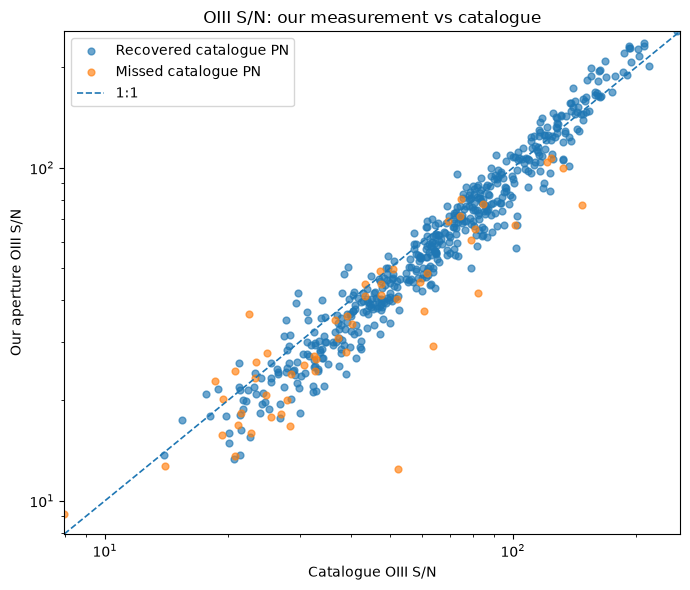

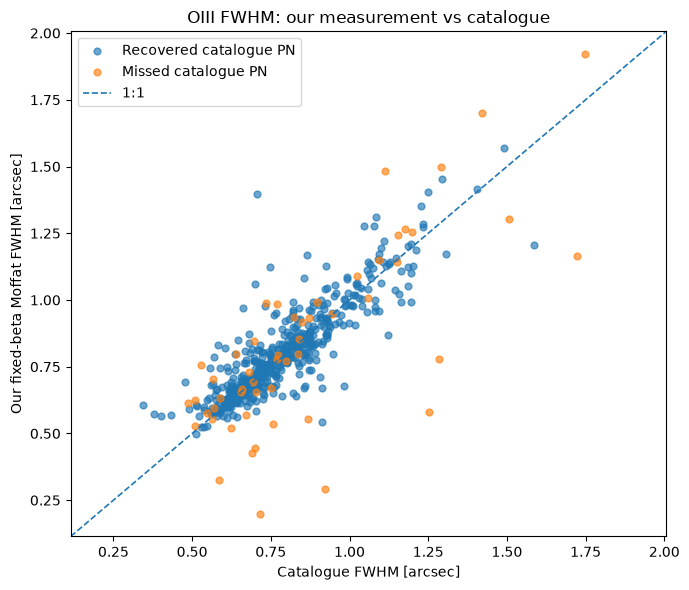

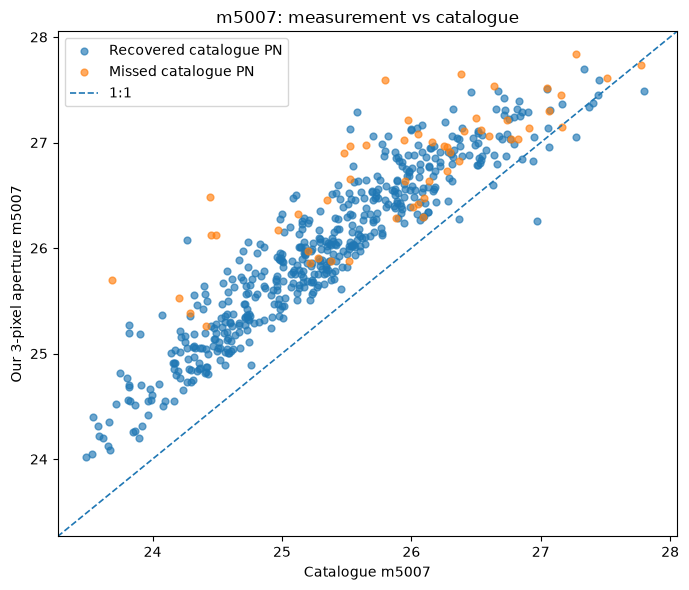

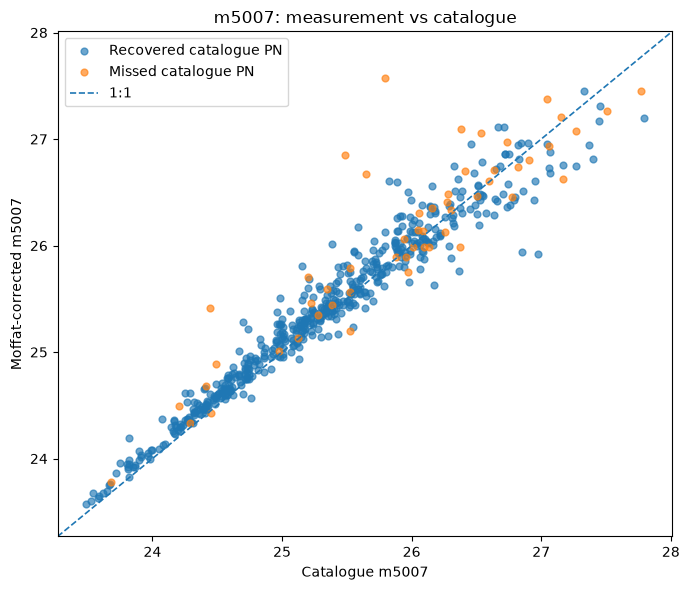

Median raw-aperture m5007 - catalogue m5007: +0.629 mag


,population,quantity,N,spearman_rho,median_ours_over_catalog,median_fractional_difference,median_ours_minus_catalog
0,Recovered catalogue PN,OIII S/N,518,0.976866,0.917386,-0.082614,-4.290174
1,Recovered catalogue PN,FWHM,518,0.864020,1.011017,0.011017,0.008849
2,Recovered catalogue PN,m5007 (3-pix aperture),518,0.941945,NaN,NaN,0.627753
3,Recovered catalogue PN,m5007 (Moffat corrected),518,0.978732,NaN,NaN,0.078012
4,Missed catalogue PN,OIII S/N,53,0.867038,0.838625,-0.161375,-5.923015
5,Missed catalogue PN,FWHM,53,0.712924,1.027512,0.027512,0.021240
6,Missed catalogue PN,m5007 (3-pix aperture),53,0.839219,NaN,NaN,0.678926
7,Missed catalogue PN,m5007 (Moffat corrected),53,0.860103,NaN,NaN,0.052779
8,All catalogue PNe,OIII S/N,571,0.972327,0.915224,-0.084776,-4.384330
9,All catalogue PNe,FWHM,571,0.843071,1.011173,0.011173,0.009106


Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/catalog_vs_our_measurements_v4.2.csv


,object_id,population,catalog_oiii_snr,oiii_snr,catalog_fwhm_arcsec,moffat_fwhm_arcsec,catalog_m5007,m5007_aperture,m5007_moffat_corrected,m5007_aperture_err,m5007_aperture_minus_catalog,m5007_corrected_minus_catalog,oiii_snr_ours_over_catalog,fwhm_ours_over_catalog
0,PN_1,Recovered catalogue PN,95.148,84.392774,0.956,1.027670,24.724,25.636408,24.750305,0.012865,0.912408,0.026305,0.886963,1.074968
1,PN_2,Recovered catalogue PN,81.816,74.710766,0.923,1.042946,25.008,25.863208,24.956833,0.014533,0.855208,-0.051167,0.913156,1.129953
2,PN_3,Recovered catalogue PN,132.907,119.322079,0.786,0.792924,24.709,25.472369,24.901381,0.009099,0.763369,0.192381,0.897786,1.008810
3,PN_4,Recovered catalogue PN,48.006,35.217418,1.080,0.958542,25.433,26.596738,25.803018,0.030830,1.163738,0.370018,0.733605,0.887539
4,PN_5,Recovered catalogue PN,37.488,30.754014,1.083,1.310037,25.789,26.869015,25.620870,0.035304,1.080015,-0.168130,0.820370,1.209637
5,PN_6,Recovered catalogue PN,49.057,40.594358,1.059,1.142308,25.518,26.526269,25.489715,0.026746,1.008269,-0.028285,0.827494,1.078667
6,PN_7,Recovered catalogue PN,64.879,55.915205,1.077,1.275582,25.129,26.136224,24.930618,0.019418,1.007224,-0.198382,0.861838,1.184384
7,PN_8,Recovered catalogue PN,37.943,33.681566,0.879,0.959750,25.985,26.719177,25.923835,0.032235,0.734177,-0.061165,0.887689,1.091866
8,PN_9,Recovered catalogue PN,44.530,39.087636,0.902,0.982506,26.110,26.865500,26.039648,0.027777,0.755500,-0.070352,0.877782,1.089253
9,PN_10,Recovered catalogue PN,84.059,66.544872,1.099,1.196217,25.168,26.284355,25.178588,0.016316,1.116355,0.010588,0.791645,1.088460


In [16]:
# Catalogue comparison uses catalogue objects only; unmatched candidates have no reference values.
cat_compare = diagnostic_table[
    diagnostic_table["population"].isin(["Recovered catalogue PN", "Missed catalogue PN"])
].copy()

print(f"Pixel scale used for FWHM conversion: {PIXEL_SCALE_ARCSEC:.5f} arcsec/pixel")

# ---------- OIII S/N: our aperture S/N vs catalogue ----------
snr_cmp = cat_compare[
    np.isfinite(cat_compare["catalog_oiii_snr"])
    & np.isfinite(cat_compare["oiii_snr"])
    & (cat_compare["catalog_oiii_snr"] > 0)
    & (cat_compare["oiii_snr"] > 0)
].copy()

plt.figure(figsize=(7, 6))
for population in ["Recovered catalogue PN", "Missed catalogue PN"]:
    g = snr_cmp[snr_cmp["population"] == population]
    if len(g):
        plt.scatter(g["catalog_oiii_snr"], g["oiii_snr"], s=24, alpha=0.65, label=population)
if len(snr_cmp):
    lo = max(0.5, min(snr_cmp["catalog_oiii_snr"].min(), snr_cmp["oiii_snr"].min()))
    hi = max(snr_cmp["catalog_oiii_snr"].max(), snr_cmp["oiii_snr"].max())
    plt.plot([lo, hi], [lo, hi], "--", linewidth=1.2, label="1:1")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlim(lo, hi)
    plt.ylim(lo, hi)
plt.xlabel("Catalogue OIII S/N")
plt.ylabel("Our aperture OIII S/N")
plt.title("OIII S/N: our measurement vs catalogue")
plt.legend()
plt.tight_layout()
plt.show()

# ---------- FWHM: our fixed-beta Moffat vs catalogue ----------
fwhm_cmp = cat_compare[
    np.isfinite(cat_compare["catalog_fwhm_arcsec"])
    & np.isfinite(cat_compare["moffat_fwhm_arcsec"])
    & (cat_compare["catalog_fwhm_arcsec"] > 0)
    & (cat_compare["moffat_fwhm_arcsec"] > 0)
].copy()

plt.figure(figsize=(7, 6))
for population in ["Recovered catalogue PN", "Missed catalogue PN"]:
    g = fwhm_cmp[fwhm_cmp["population"] == population]
    if len(g):
        plt.scatter(g["catalog_fwhm_arcsec"], g["moffat_fwhm_arcsec"], s=24, alpha=0.65, label=population)
if len(fwhm_cmp):
    lo = min(fwhm_cmp["catalog_fwhm_arcsec"].min(), fwhm_cmp["moffat_fwhm_arcsec"].min())
    hi = max(fwhm_cmp["catalog_fwhm_arcsec"].max(), fwhm_cmp["moffat_fwhm_arcsec"].max())
    pad = 0.05 * (hi - lo) if hi > lo else 0.05
    lo, hi = max(0, lo - pad), hi + pad
    plt.plot([lo, hi], [lo, hi], "--", linewidth=1.2, label="1:1")
    plt.xlim(lo, hi)
    plt.ylim(lo, hi)
plt.xlabel("Catalogue FWHM [arcsec]")
plt.ylabel("Our fixed-beta Moffat FWHM [arcsec]")
plt.title("OIII FWHM: our measurement vs catalogue")
plt.legend()
plt.tight_layout()
plt.show()


# ---------- m5007: our measurement vs catalogue ----------
# The raw aperture magnitude is shown first. Because the catalogue may use a
# total/PSF-corrected flux, a second panel uses our Moffat aperture correction.
for ours_col, ours_label, title_suffix in [
    ("m5007_aperture", "Our 3-pixel aperture m5007", "raw aperture"),
    ("m5007_moffat_corrected", "Moffat-corrected m5007", "Moffat aperture-corrected"),
]:
    mag_cmp = cat_compare[
        np.isfinite(cat_compare["catalog_m5007"])
        & np.isfinite(cat_compare[ours_col])
    ].copy()

    plt.figure(figsize=(7, 6))
    for population in ["Recovered catalogue PN", "Missed catalogue PN"]:
        g = mag_cmp[mag_cmp["population"] == population]
        if len(g):
            plt.scatter(g["catalog_m5007"], g[ours_col], s=24, alpha=0.65, label=population)
    if len(mag_cmp):
        lo = min(mag_cmp["catalog_m5007"].min(), mag_cmp[ours_col].min())
        hi = max(mag_cmp["catalog_m5007"].max(), mag_cmp[ours_col].max())
        pad = 0.05 * (hi - lo) if hi > lo else 0.1
        lo, hi = lo - pad, hi + pad
        plt.plot([lo, hi], [lo, hi], "--", linewidth=1.2, label="1:1")
        plt.xlim(lo, hi)
        plt.ylim(lo, hi)
    plt.xlabel("Catalogue m5007")
    plt.ylabel(ours_label)
    plt.title(f"m5007: measurement vs catalogue")
    plt.legend()
    plt.tight_layout()
    plt.show()


# A multi-magnitude global offset is usually a flux-unit problem, not aperture correction.
mag_unit_check = cat_compare[
    np.isfinite(cat_compare["catalog_m5007"]) & np.isfinite(cat_compare["m5007_aperture"])
]
if len(mag_unit_check):
    med_dm = float(np.nanmedian(mag_unit_check["m5007_aperture"] - mag_unit_check["catalog_m5007"]))
    print(f"Median raw-aperture m5007 - catalogue m5007: {med_dm:+.3f} mag")
    if abs(med_dm) > 5:
        print("WARNING: |median delta m5007| > 5 mag. Check OIII_FLUX_TO_CGS and the FITS BUNIT before interpreting the comparison.")

# ---------- Compact numerical summary ----------
def comparison_stats(df, ours, catalog, name, magnitude=False):
    x = df[catalog].to_numpy(float)
    y = df[ours].to_numpy(float)
    good = np.isfinite(x) & np.isfinite(y)
    if not magnitude:
        good &= (x > 0)
    x, y = x[good], y[good]
    if len(x) == 0:
        return {"quantity": name, "N": 0, "spearman_rho": np.nan,
                "median_ours_over_catalog": np.nan, "median_fractional_difference": np.nan,
                "median_ours_minus_catalog": np.nan}
    rho = spearmanr(x, y).statistic if len(x) >= 3 else np.nan
    if magnitude:
        median_ratio = np.nan
        median_fractional = np.nan
    else:
        median_ratio = np.nanmedian(y / x)
        median_fractional = np.nanmedian((y - x) / x)
    return {
        "quantity": name,
        "N": len(x),
        "spearman_rho": rho,
        "median_ours_over_catalog": median_ratio,
        "median_fractional_difference": median_fractional,
        "median_ours_minus_catalog": np.nanmedian(y - x),
    }

comparison_rows = []
for population in ["Recovered catalogue PN", "Missed catalogue PN", "All catalogue PNe"]:
    g = cat_compare if population == "All catalogue PNe" else cat_compare[cat_compare["population"] == population]
    for rec in [
        comparison_stats(g, "oiii_snr", "catalog_oiii_snr", "OIII S/N"),
        comparison_stats(g, "moffat_fwhm_arcsec", "catalog_fwhm_arcsec", "FWHM"),
        comparison_stats(g, "m5007_aperture", "catalog_m5007", "m5007 (3-pix aperture)", magnitude=True),
        comparison_stats(g, "m5007_moffat_corrected", "catalog_m5007", "m5007 (Moffat corrected)", magnitude=True),
    ]:
        rec["population"] = population
        comparison_rows.append(rec)

catalog_comparison_summary = pd.DataFrame(comparison_rows)[
    ["population", "quantity", "N", "spearman_rho", "median_ours_over_catalog", "median_fractional_difference", "median_ours_minus_catalog"]
]
display(catalog_comparison_summary)
catalog_comparison_summary.to_csv(OUTPUT_DIR / "catalog_vs_our_measurements_v4.2.csv", index=False)
print("Saved:", OUTPUT_DIR / "catalog_vs_our_measurements_v4.2.csv")

# Optional per-object table for inspection.
cols = [
    "object_id", "population", "catalog_oiii_snr", "oiii_snr",
    "catalog_fwhm_arcsec", "moffat_fwhm_arcsec",
    "catalog_m5007", "m5007_aperture", "m5007_moffat_corrected",
    "m5007_aperture_err", "m5007_aperture_minus_catalog", "m5007_corrected_minus_catalog",
    "oiii_snr_ours_over_catalog", "fwhm_ours_over_catalog",
]
display(cat_compare[cols].head(20))


## Why some line ratios are unavailable

A displayed ratio is intentionally withheld unless both the numerator line and OIII have positive background-subtracted flux and S/N > 2. The table below reports the exact reason for unavailable ratios, so `NaN` is not interpreted as a numerical line ratio.


In [17]:
for ratio, status in [
    ("Hb/OIII", "hb_over_oiii_status"),
    ("Ha/OIII", "ha_over_oiii_status"),
    ("NII/OIII", "nii_over_oiii_status"),
]:
    print(f"\n{ratio} status:")
    display(diagnostic_table.groupby(["population", status]).size().rename("N").reset_index())



Hb/OIII status:


,population,hb_over_oiii_status,N
0,Missed catalogue PN,Hb S/N <= 2,3
1,Missed catalogue PN,Hb flux <= 0,4
2,Missed catalogue PN,ok,46
3,Recovered catalogue PN,Hb S/N <= 2,51
4,Recovered catalogue PN,Hb flux <= 0,54
5,Recovered catalogue PN,ok,413
6,Unmatched candidate,Hb S/N <= 2,82
7,Unmatched candidate,Hb flux <= 0,183
8,Unmatched candidate,OIII S/N <= 2,3
9,Unmatched candidate,OIII flux <= 0,6



Ha/OIII status:


,population,ha_over_oiii_status,N
0,Missed catalogue PN,Ha S/N <= 2,1
1,Missed catalogue PN,Ha flux <= 0,2
2,Missed catalogue PN,ok,50
3,Recovered catalogue PN,Ha S/N <= 2,6
4,Recovered catalogue PN,Ha flux <= 0,36
5,Recovered catalogue PN,ok,476
6,Unmatched candidate,Ha S/N <= 2,19
7,Unmatched candidate,Ha flux <= 0,139
8,Unmatched candidate,OIII S/N <= 2,2
9,Unmatched candidate,OIII flux <= 0,6



NII/OIII status:


,population,nii_over_oiii_status,N
0,Missed catalogue PN,NII S/N <= 2,1
1,Missed catalogue PN,NII flux <= 0,3
2,Missed catalogue PN,ok,49
3,Recovered catalogue PN,NII S/N <= 2,34
4,Recovered catalogue PN,NII flux <= 0,76
5,Recovered catalogue PN,ok,408
6,Unmatched candidate,NII S/N <= 2,23
7,Unmatched candidate,NII flux <= 0,129
8,Unmatched candidate,OIII S/N <= 2,4
9,Unmatched candidate,OIII flux <= 0,6


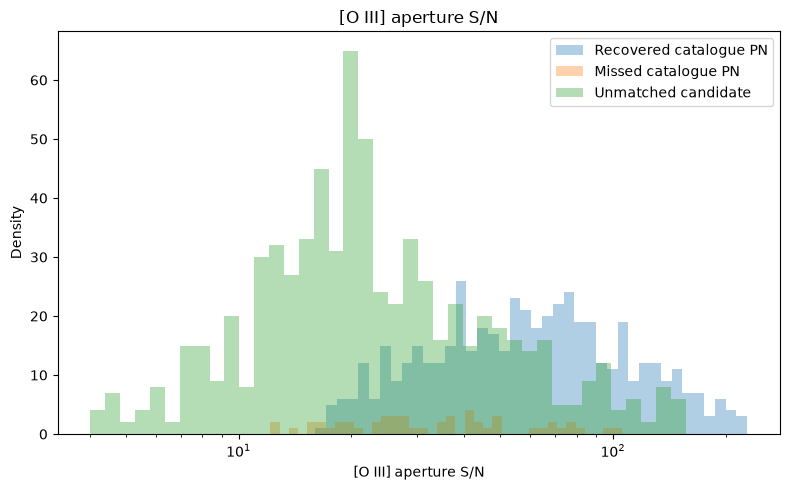

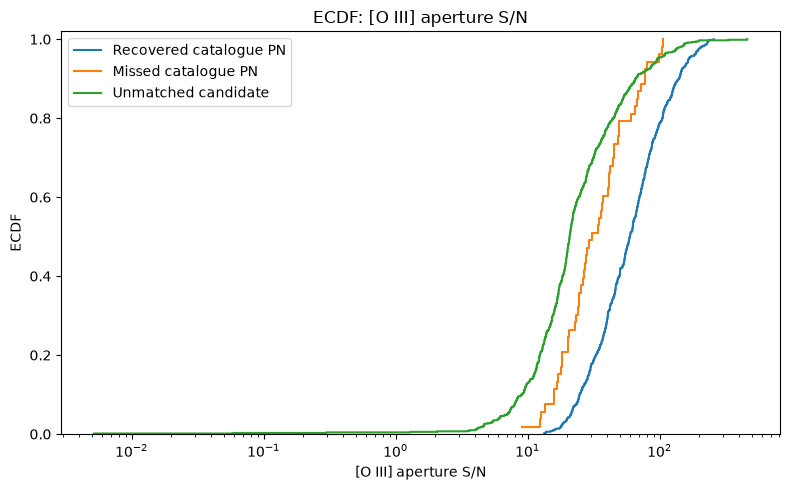

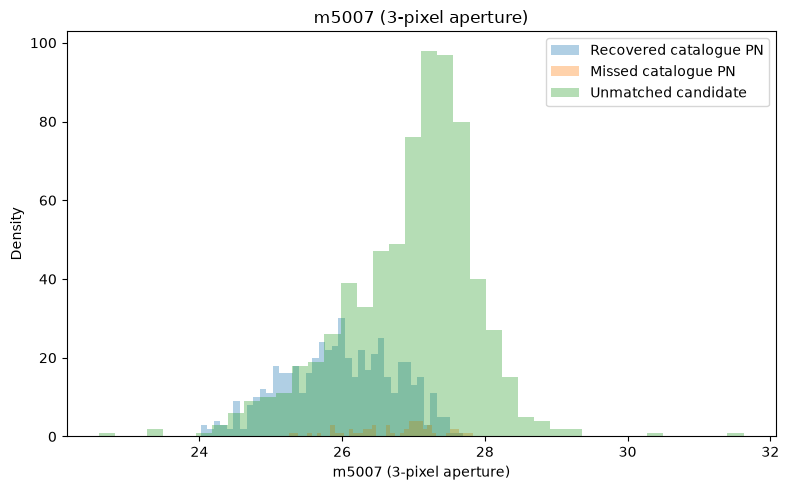

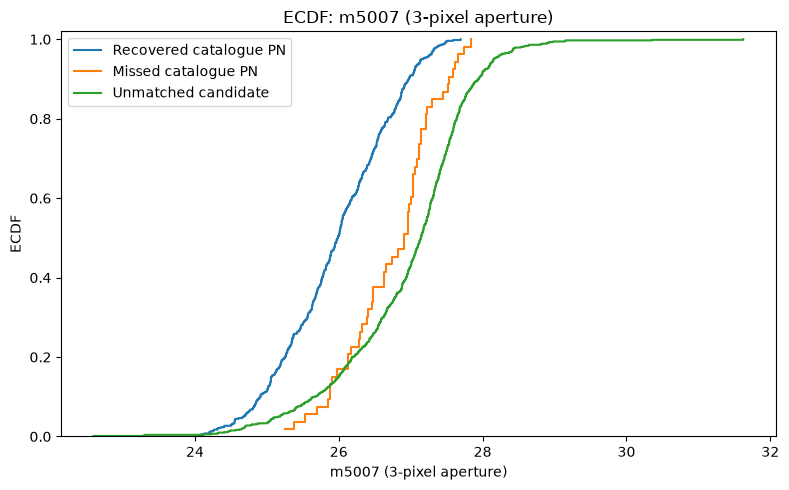

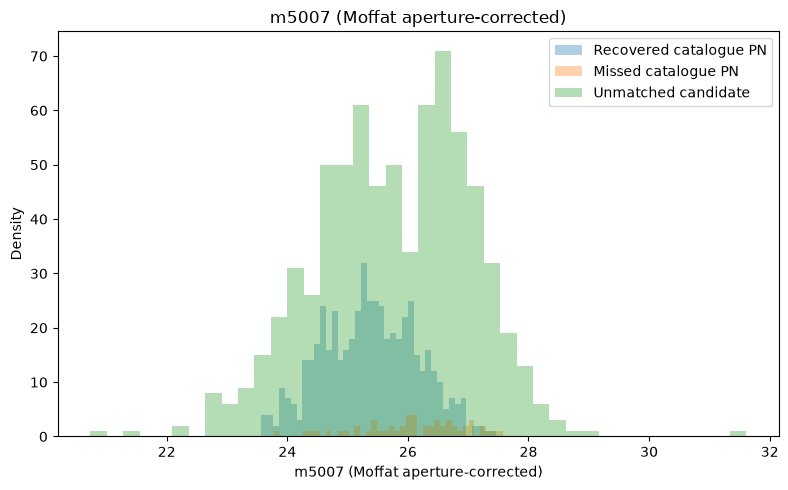

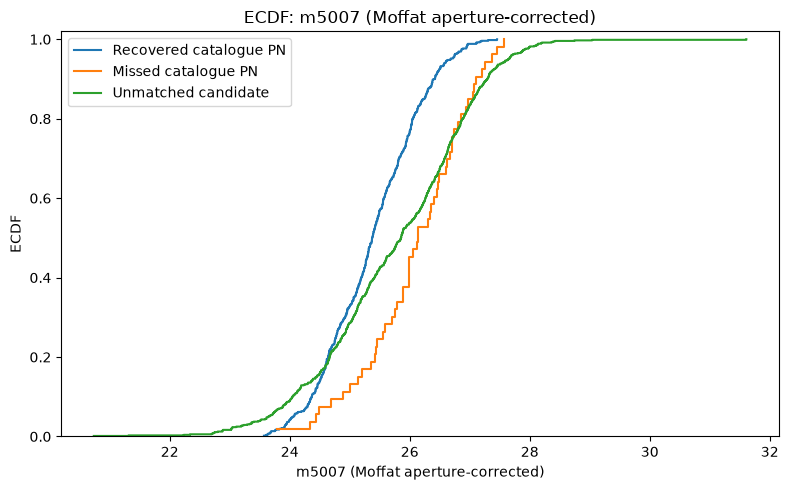

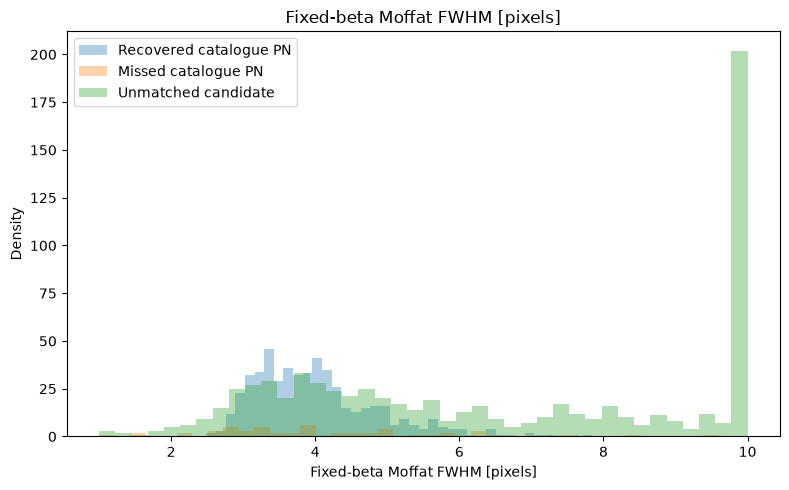

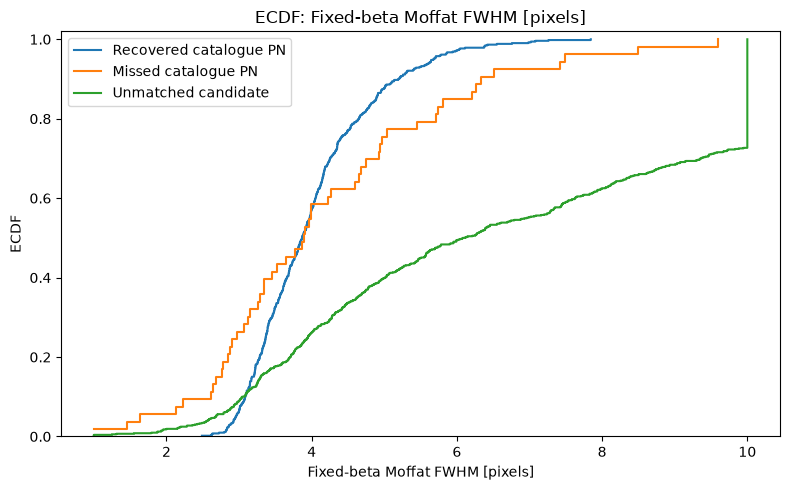

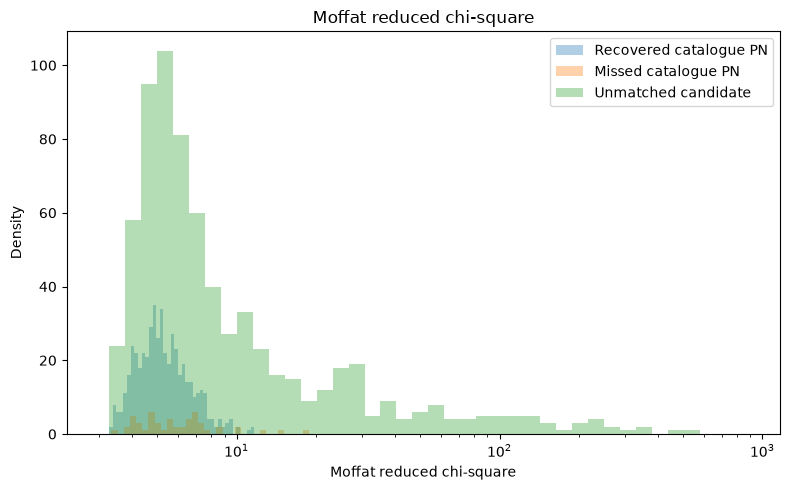

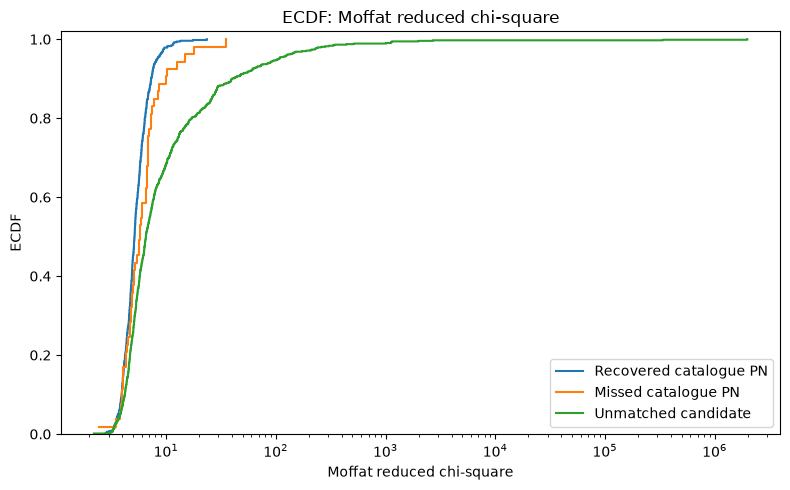

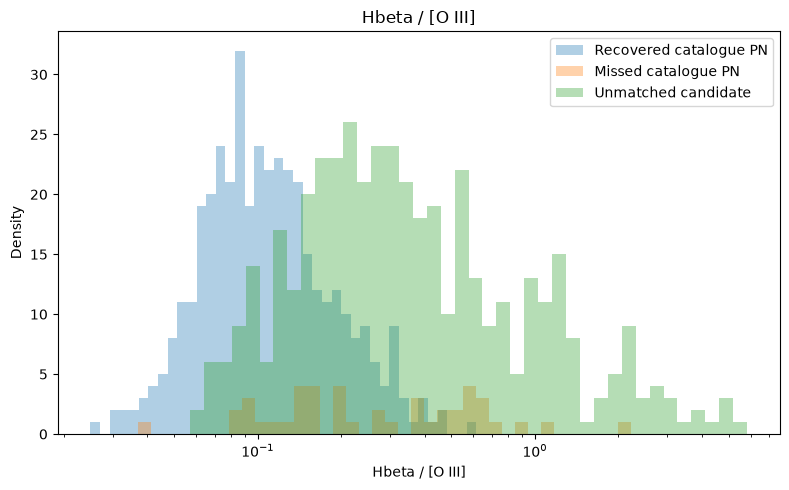

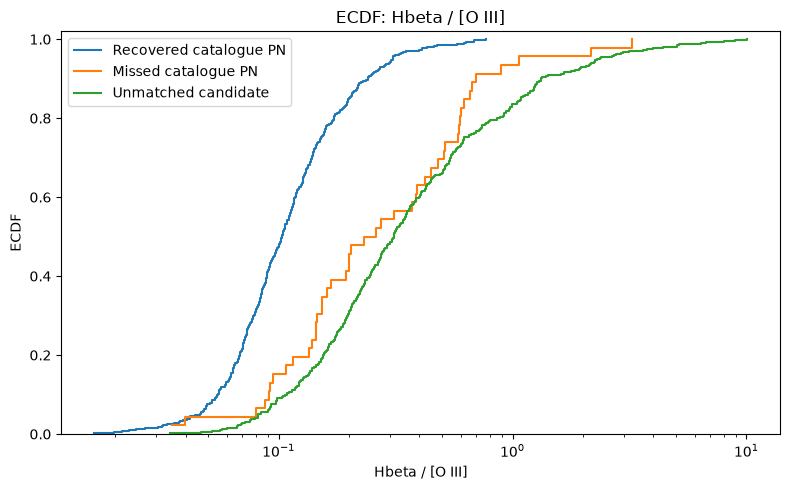

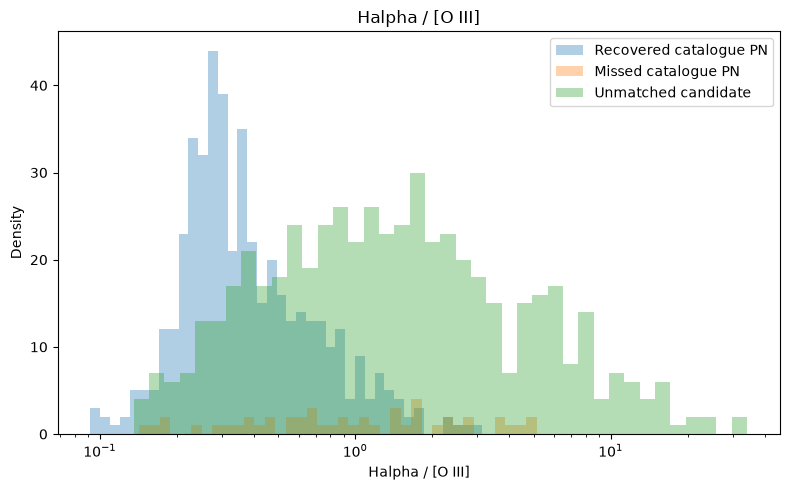

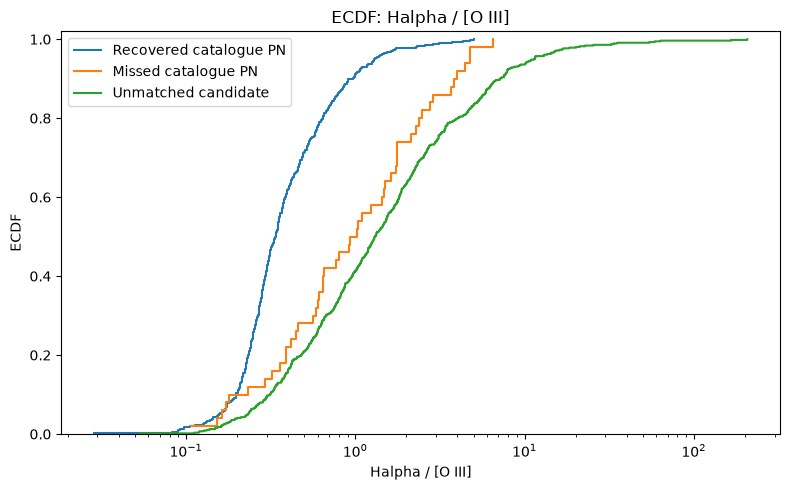

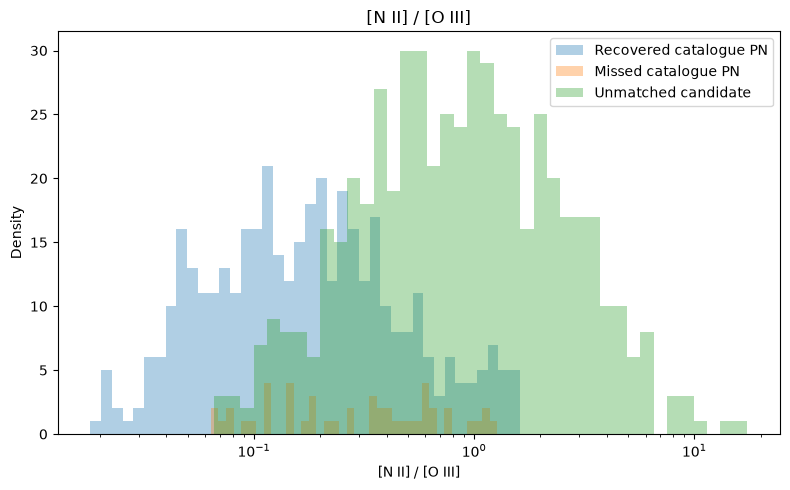

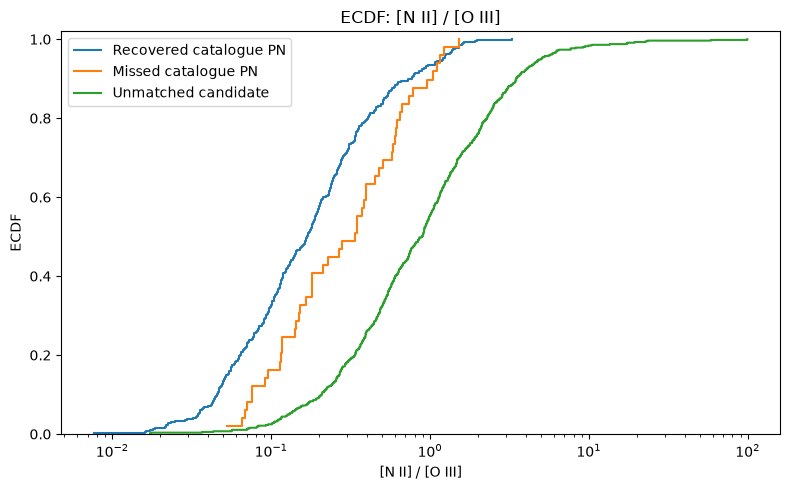

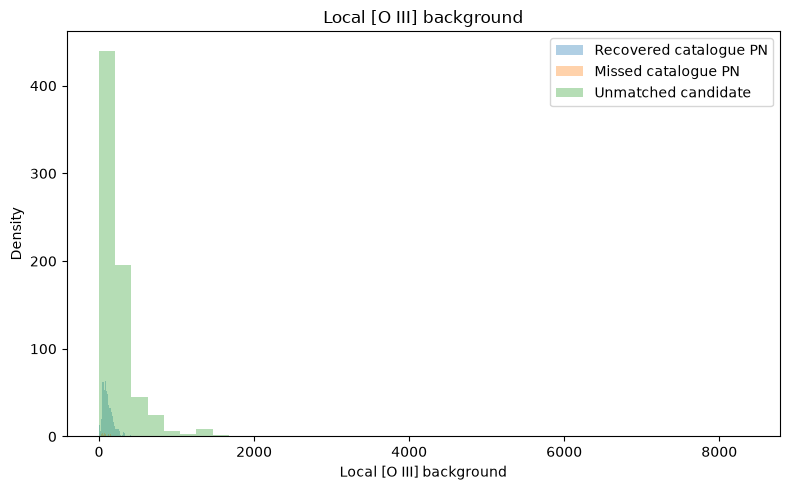

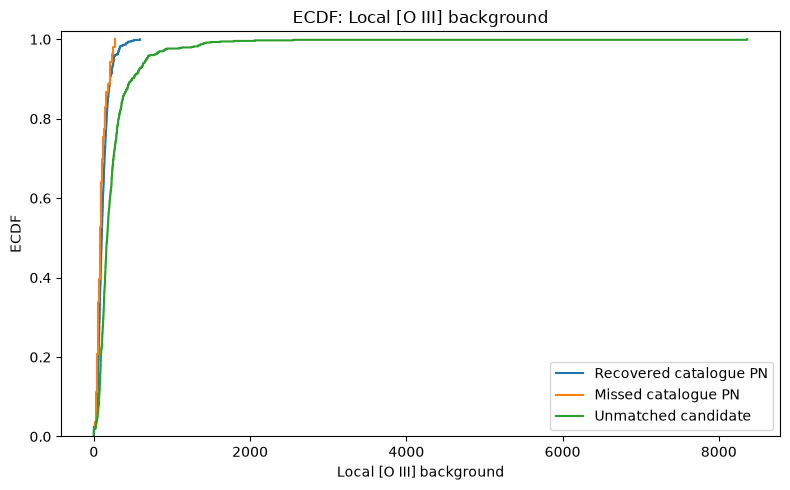

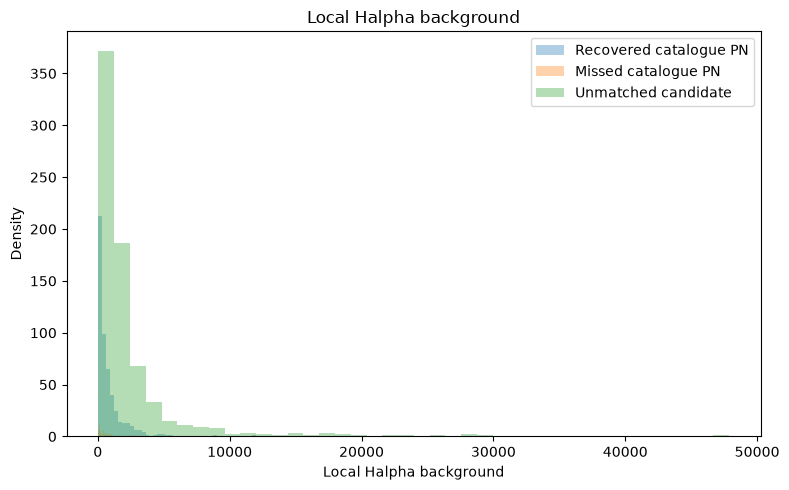

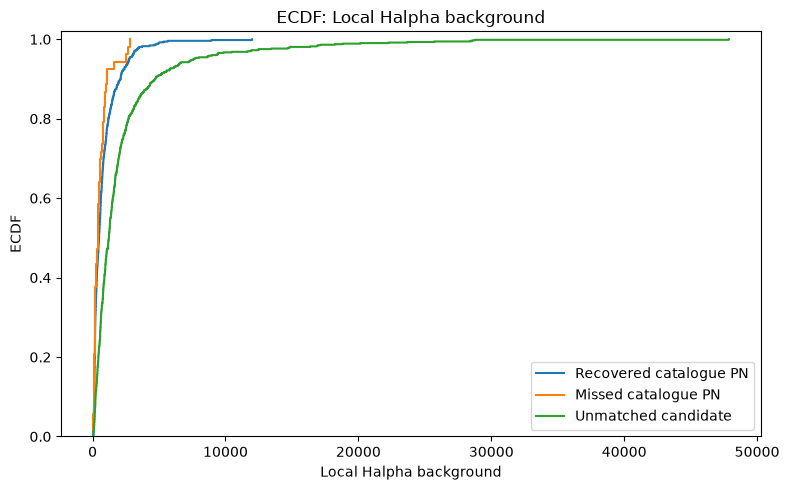

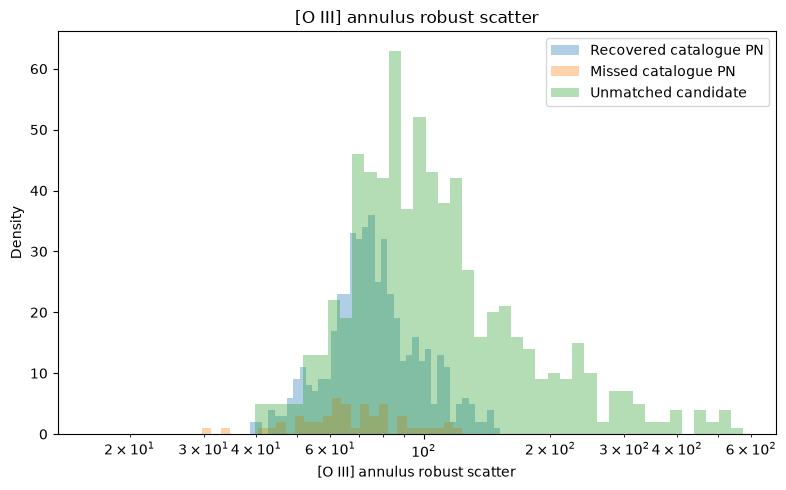

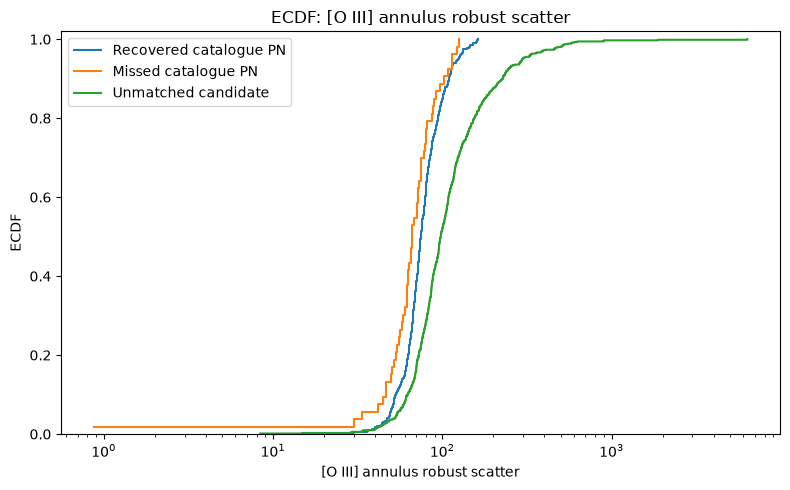

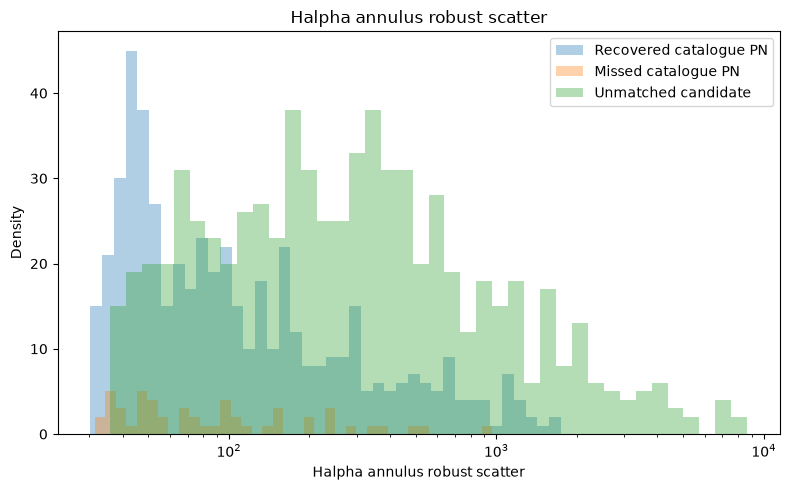

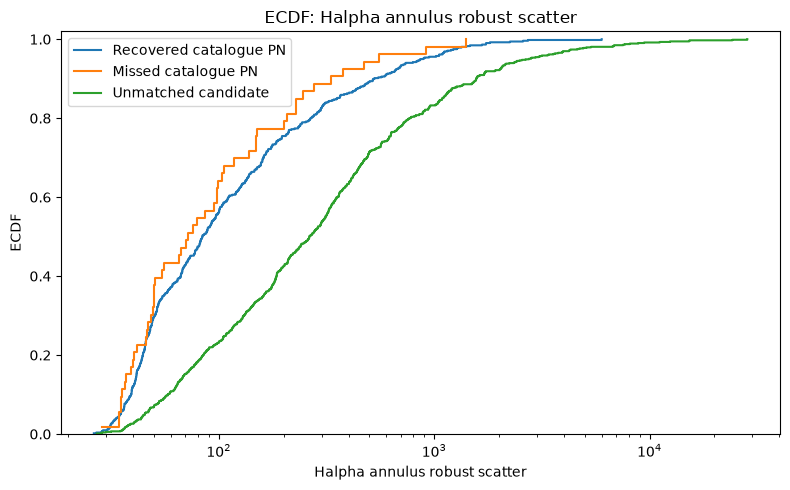

In [19]:
POPULATION_ORDER = [
    "Recovered catalogue PN",
    "Missed catalogue PN",
    "Unmatched candidate",
]


def finite_metric(group, column, positive_only=False):
    vals = group[column].to_numpy(dtype=float)
    vals = vals[np.isfinite(vals)]
    if positive_only:
        vals = vals[vals > 0]
    return vals


def plot_metric_histogram(column, xlabel, log_x=False, bins=40):
    plt.figure(figsize=(8, 5))
    any_data = False
    for population in POPULATION_ORDER:
        group = analysis_table[analysis_table["population"] == population]
        vals = finite_metric(group, column, positive_only=log_x)
        if len(vals) == 0:
            continue
        any_data = True
        if log_x:
            lo, hi = np.percentile(vals, [1, 99])
            lo = max(lo, np.min(vals[vals > 0]))
            if hi <= lo:
                hi = lo * 1.01
            edges = np.logspace(np.log10(lo), np.log10(hi), bins + 1)
            plt.hist(vals, bins=edges, density=False, alpha=0.35, label=population)
        else:
            plt.hist(vals, bins=bins, density=False, alpha=0.35, label=population)
    if not any_data:
        return
    if log_x:
        plt.xscale("log")
    plt.xlabel(xlabel)
    plt.ylabel("Density")
    plt.title(f"{xlabel}")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_metric_ecdf(column, xlabel, log_x=False):
    plt.figure(figsize=(8, 5))
    any_data = False
    for population in POPULATION_ORDER:
        group = analysis_table[analysis_table["population"] == population]
        vals = finite_metric(group, column, positive_only=log_x)
        if len(vals) == 0:
            continue
        any_data = True
        vals = np.sort(vals)
        y = np.arange(1, len(vals) + 1) / len(vals)
        plt.step(vals, y, where="post", label=population)
    if not any_data:
        return
    if log_x:
        plt.xscale("log")
    plt.xlabel(xlabel)
    plt.ylabel("ECDF")
    plt.ylim(0, 1.02)
    plt.title(f"ECDF: {xlabel}")
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_specs = [
    ("oiii_snr", "[O III] aperture S/N", True),
    ("m5007_aperture", "m5007 (3-pixel aperture)", False),
    ("m5007_moffat_corrected", "m5007 (Moffat aperture-corrected)", False),
    ("moffat_fwhm_pix", "Fixed-beta Moffat FWHM [pixels]", False),
    ("moffat_reduced_chi2", "Moffat reduced chi-square", True),
    ("hb_over_oiii", "Hbeta / [O III]", True),
    ("ha_over_oiii", "Halpha / [O III]", True),
    ("nii_over_oiii", "[N II] / [O III]", True),
    ("oiii_bkg", "Local [O III] background", False),
    ("ha_bkg", "Local Halpha background", False),
    ("oiii_bkg_scatter", "[O III] annulus robust scatter", True),
    ("ha_bkg_scatter", "Halpha annulus robust scatter", True),
]

for column, xlabel, log_x in plot_specs:
    plot_metric_histogram(column, xlabel, log_x=log_x)
    plot_metric_ecdf(column, xlabel, log_x=log_x)


## Spatial distribution and edge diagnostics

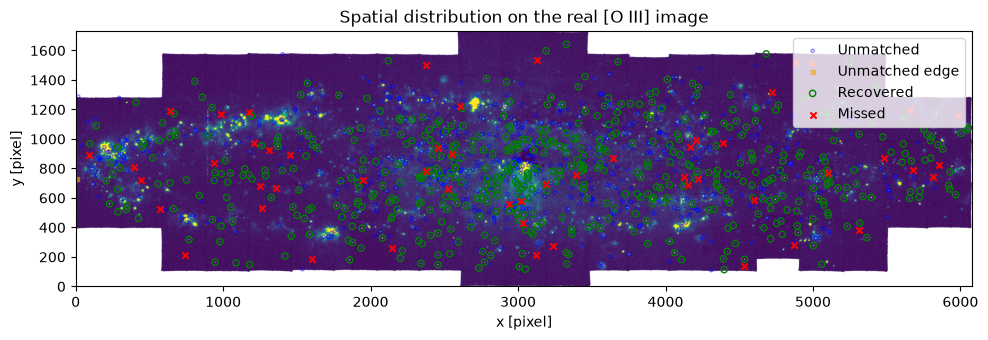

,population,edge_count,total,edge_fraction
0,Missed catalogue PN,0,53,0.00000
1,Recovered catalogue PN,0,518,0.00000
2,Unmatched candidate,1,730,0.00137


In [19]:
finite_oiii = oiii_flux[np.isfinite(oiii_flux)]
vmin, vmax = np.percentile(finite_oiii, [5, 99.5]) if len(finite_oiii) else (0, 1)

plt.figure(figsize=(10, 10))
plt.imshow(oiii_flux, origin="lower", vmin=vmin, vmax=vmax)

unmatched_nonedge = diagnostic_table[
    (diagnostic_table["population"] == "Unmatched candidate") & (~diagnostic_table["edge_object"])
]
unmatched_edge = diagnostic_table[
    (diagnostic_table["population"] == "Unmatched candidate") & (diagnostic_table["edge_object"])
]
recovered = diagnostic_table[diagnostic_table["population"] == "Recovered catalogue PN"]
missed = diagnostic_table[diagnostic_table["population"] == "Missed catalogue PN"]

plt.scatter(unmatched_nonedge["center_x"], unmatched_nonedge["center_y"], s=5, label="Unmatched", alpha=0.45, facecolors="None", edgecolors="blue")
plt.scatter(unmatched_edge["center_x"], unmatched_edge["center_y"], s=12, marker="s", alpha=0.55, label="Unmatched edge", color="orange")
plt.scatter(recovered["center_x"], recovered["center_y"], s=20, marker="o", edgecolors="g", facecolors="None", label="Recovered")
plt.scatter(missed["center_x"], missed["center_y"], s=20, marker="x", label="Missed", color="r")
plt.xlabel("x [pixel]")
plt.ylabel("y [pixel]")
plt.title("Spatial distribution on the real [O III] image")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

edge_summary = (
    diagnostic_table.groupby("population")["edge_object"]
    .agg(edge_count="sum", total="count")
    .reset_index()
)
edge_summary["edge_fraction"] = edge_summary["edge_count"] / edge_summary["total"]
display(edge_summary)


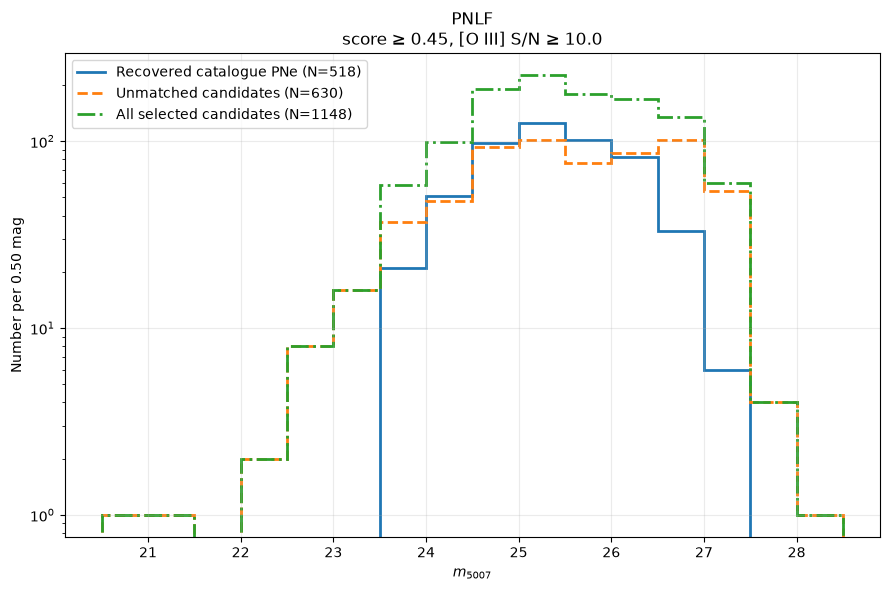

In [26]:
# ============================================================
# Observed PN luminosity function from inference outputs
# ============================================================

PNLF_MAG_COLUMN = "m5007_moffat_corrected"
PNLF_BIN_WIDTH = 0.5

# Candidate-selection settings.
PNLF_SCORE_MIN = DIAGNOSTIC_THRESHOLD
PNLF_SNR_MIN = 10.0

pnlf_table = diagnostic_table[diagnostic_table["population"].isin(["Recovered catalogue PN", "Unmatched candidate"])
    & (~diagnostic_table["edge_object"])
    & (diagnostic_table["network_score"] >= PNLF_SCORE_MIN)
    & (diagnostic_table["oiii_snr"] >= PNLF_SNR_MIN)
    & np.isfinite(diagnostic_table[PNLF_MAG_COLUMN])].copy()

recovered_mags = pnlf_table.loc[
    pnlf_table["population"] == "Recovered catalogue PN",
    PNLF_MAG_COLUMN,].to_numpy(float)

unmatched_mags = pnlf_table.loc[
    pnlf_table["population"] == "Unmatched candidate",
    PNLF_MAG_COLUMN,].to_numpy(float)

all_mags = pnlf_table[PNLF_MAG_COLUMN].to_numpy(float)

if len(all_mags) == 0:
    raise RuntimeError("No candidates passed the PNLF selection.")

# Use fixed-width magnitude bins.
bright_edge = (np.floor(np.nanmin(all_mags) / PNLF_BIN_WIDTH) * PNLF_BIN_WIDTH)
faint_edge = (np.ceil(np.nanmax(all_mags) / PNLF_BIN_WIDTH) * PNLF_BIN_WIDTH)
bins = np.arange(bright_edge, faint_edge + PNLF_BIN_WIDTH, PNLF_BIN_WIDTH)

recovered_counts, _ = np.histogram(recovered_mags, bins=bins)
unmatched_counts, _ = np.histogram(unmatched_mags, bins=bins)
total_counts = recovered_counts + unmatched_counts
bin_centres = 0.5 * (bins[:-1] + bins[1:])

fig, ax = plt.subplots(figsize=(9, 6))

# Show the two populations separately.
ax.stairs(recovered_counts,bins,linewidth=2,label=f"Recovered catalogue PNe (N={len(recovered_mags)})")
ax.stairs(unmatched_counts, bins, linewidth=2, linestyle="--", label=f"Unmatched candidates (N={len(unmatched_mags)})")
ax.stairs(total_counts, bins, linewidth=2, linestyle="-.", label=f"All selected candidates (N={len(all_mags)})")

ax.set_xlabel(r"$m_{5007}$")
ax.set_ylabel(f"Number per {PNLF_BIN_WIDTH:.2f} mag")
ax.set_title("PNLF\n"f"score ≥ {PNLF_SCORE_MIN:.2f}, "f"[O III] S/N ≥ {PNLF_SNR_MIN:.1f}")

ax.set_yscale('log')

ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

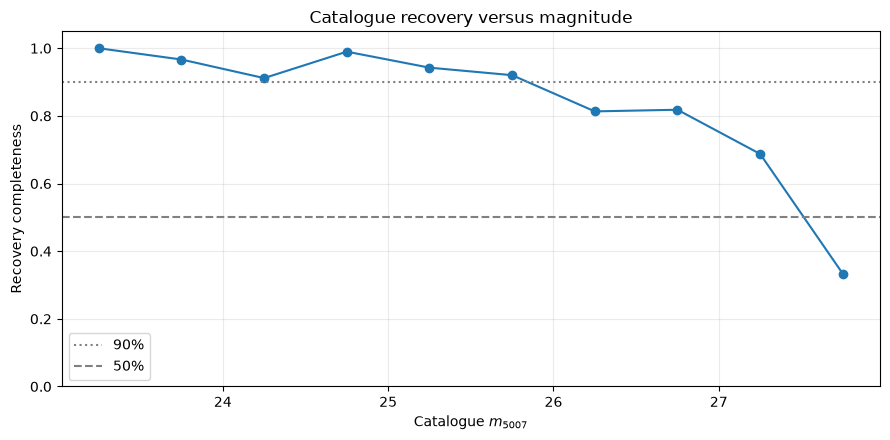

In [21]:
# ============================================================
# Catalogue recovery completeness versus m5007
# ============================================================

catalogue_objects = diagnostic_table[
    diagnostic_table["population"].isin(
        ["Recovered catalogue PN", "Missed catalogue PN"]
    )
    & np.isfinite(diagnostic_table["catalog_m5007"])
].copy()

catalogue_objects["recovered"] = (
    catalogue_objects["population"] == "Recovered catalogue PN"
)

catalogue_mags = catalogue_objects["catalog_m5007"].to_numpy(float)

cat_bright = (
    np.floor(np.nanmin(catalogue_mags) / PNLF_BIN_WIDTH)
    * PNLF_BIN_WIDTH
)
cat_faint = (
    np.ceil(np.nanmax(catalogue_mags) / PNLF_BIN_WIDTH)
    * PNLF_BIN_WIDTH
)

catalogue_bins = np.arange(
    cat_bright,
    cat_faint + PNLF_BIN_WIDTH,
    PNLF_BIN_WIDTH,
)

total_catalogue, _ = np.histogram(
    catalogue_objects["catalog_m5007"],
    bins=catalogue_bins,
)

recovered_catalogue, _ = np.histogram(
    catalogue_objects.loc[
        catalogue_objects["recovered"],
        "catalog_m5007",
    ],
    bins=catalogue_bins,
)

completeness = np.divide(
    recovered_catalogue,
    total_catalogue,
    out=np.full(len(total_catalogue), np.nan),
    where=total_catalogue > 0,
)

catalogue_centres = 0.5 * (
    catalogue_bins[:-1] + catalogue_bins[1:]
)

plt.figure(figsize=(9, 4.5))

plt.plot(
    catalogue_centres,
    completeness,
    "o-",
)

plt.axhline(0.9, linestyle=":", color="grey", label="90%")
plt.axhline(0.5, linestyle="--", color="grey", label="50%")

plt.ylim(0, 1.05)
plt.xlabel(r"Catalogue $m_{5007}$")
plt.ylabel("Recovery completeness")
plt.title("Catalogue recovery versus magnitude")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Interpretation guide

Use the diagnostics in this order:

1. **FWHM + reduced χ²:** if unmatched candidates are broader or systematically poorer Moffat fits than recovered PNe, morphology is a major discriminator.
2. **Line-ratio distributions:** if morphology overlaps but Hβ/[O III], Hα/[O III], or [N II]/[O III] differs, the synthetic spectral coverage is the likely bottleneck.
3. **Background level/scatter + spatial map:** if unmatched candidates cluster in high-background or highly structured regions, real environmental context is driving the domain gap.
4. **Missed PNe:** compare their local network score, morphology, line ratios, and environment with recovered PNe to identify what the model suppresses.
5. If unmatched candidates overlap recovered catalogue PNe in morphology, spectral ratios, S/N, and environment, do not assume they are false positives solely because they are absent from the catalogue; their astrophysical nature needs separate validation.

No PSF-normalized FWHM quantity is computed, by design.

In [22]:
# ============================================================
# Save all recovered and missed catalogue objects as PNG pages
# ============================================================
'''
CATALOGUE_PNG_DIR = OUTPUT_DIR / "all_catalogue_object_pngs"
CATALOGUE_PNG_DIR.mkdir(parents=True, exist_ok=True)

CATALOGUE_PAGE_SIZE = 20
CATALOGUE_SCALING = "local"
CATALOGUE_DPI = 200

def catalogue_annotation_no_chi2(r):
    """Create a catalogue-object label without reduced chi-square."""

    hb_ratio = fmt_ratio_with_status(
        r,
        "hb_over_oiii",
        "hb_over_oiii_status",
        "Hb/OIII",
    )

    ha_ratio = fmt_ratio_with_status(
        r,
        "ha_over_oiii",
        "ha_over_oiii_status",
        "Ha/OIII",
    )

    nii_ratio = fmt_ratio_with_status(
        r,
        "nii_over_oiii",
        "nii_over_oiii_status",
        "NII/OIII",
    )

    return (
        f"{r['population']} | {r['object_id']}\n"
        f"score={fmt_value(r['network_score'], '.3f')}  "
        f"OIII S/N={fmt_value(r['oiii_snr'], '.1f')}\n"
        f"m5007(ap)={fmt_value(r['m5007_aperture'], '.2f')}  "
        f"FWHM={fmt_value(r['moffat_fwhm_pix'], '.2f')} px\n"
        f"{hb_ratio}  {ha_ratio}  {nii_ratio}"
    )

        
def save_all_catalogue_object_pages(
    table,
    output_dir,
    page_size=8,
    scaling="local",
    dpi=200,
):

    selected = table[
        table["population"].isin([
            "Recovered catalogue PN",
            "Missed catalogue PN",
            "Unmatched candidate"
        ])
    ].copy()

    if selected.empty:
        print("No recovered or missed catalogue objects were found.")
        return []

    # Recovered objects first, then missed; descending network score within each.
    population_order = {
        "Recovered catalogue PN": 0,
        "Missed catalogue PN": 1,
        "Unmatched candidate": 2,
    }

    selected["_population_order"] = (
        selected["population"].map(population_order)
    )

    selected = (
        selected
        .sort_values(
            ["_population_order", "network_score", "object_id"],
            ascending=[True, False, True],
            na_position="last",
        )
        .drop(columns="_population_order")
        .reset_index(drop=True)
    )

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    channel_names = list(DISPLAY_MAPS.keys())

    common_scales = (
        common_scales_for_sample(selected)
        if scaling == "common"
        else None
    )

    saved_files = []
    number_of_pages = int(np.ceil(len(selected) / page_size))

    for page_number, start in enumerate(
        range(0, len(selected), page_size),
        start=1,
    ):
        page = selected.iloc[start:start + page_size]

        fig, axes = plt.subplots(
            nrows=len(page),
            ncols=len(channel_names),
            figsize=(16, 3.2 * len(page)),
            squeeze=False,
        )

        for row_index, (_, row) in enumerate(page.iterrows()):
            for column_index, channel_name in enumerate(channel_names):
                ax = axes[row_index, column_index]
                image_map = DISPLAY_MAPS[channel_name]

                cutout, origin = extract_centered_cutout(
                    image_map,
                    row["center_x"],
                    row["center_y"],
                    size=DIAG_CUTOUT_SIZE,
                )

                if cutout is None:
                    ax.text(
                        0.5,
                        0.5,
                        "Cutout outside image",
                        ha="center",
                        va="center",
                        transform=ax.transAxes,
                    )
                    ax.axis("off")
                    continue

                if channel_name == "PN heatmap":
                    vmin, vmax = 0.0, 1.0
                elif scaling == "common":
                    vmin, vmax = common_scales[channel_name]
                else:
                    vmin, vmax = robust_limits(cutout)

                ax.imshow(
                    cutout,
                    origin="lower",
                    cmap="viridis",
                    vmin=vmin,
                    vmax=vmax,
                )

                local_x = row["center_x"] - origin[0]
                local_y = row["center_y"] - origin[1]

                ax.scatter(
                    [local_x],
                    [local_y],
                    marker="+",
                    s=65,
                    linewidths=1.4,
                    color="red",
                )

                if row_index == 0:
                    ax.set_title(channel_name)

                ax.set_xticks([])
                ax.set_yticks([])

            axes[row_index, 0].set_ylabel(
                catalogue_annotation_no_chi2(row),
                fontsize=8,
                rotation=0,
                ha="right",
                va="center",
                labelpad=12,
            )

        first_object = start + 1
        last_object = start + len(page)

        fig.suptitle(
            "All recovered and missed catalogue PNe\n"
            f"Objects {first_object}–{last_object} of {len(selected)} | "
            f"{scaling} scaling",
            fontsize=14,
        )

        fig.tight_layout(rect=[0, 0, 1, 0.96])

        output_path = output_dir / (
            f"NGC253_all_catalogue_objects_"
            f"page_{page_number:03d}_of_{number_of_pages:03d}.png"
        )

        fig.savefig(
            output_path,
            dpi=dpi,
            bbox_inches="tight",
            facecolor="white",
        )
        plt.close(fig)

        saved_files.append(output_path)
        print("Saved:", output_path)

    # Also save the exact rows included in the figures.
    catalogue_csv = output_dir / "M33_all_catalogue_objects.csv"
    selected.to_csv(catalogue_csv, index=False)
    print("Saved catalogue table:", catalogue_csv)

    print(
        f"\nSaved all {len(selected)} catalogue objects "
        f"across {len(saved_files)} PNG page(s)."
    )

    return saved_files


catalogue_png_files = save_all_catalogue_object_pages(
    table=diagnostic_table,
    output_dir=CATALOGUE_PNG_DIR,
    page_size=CATALOGUE_PAGE_SIZE,
    scaling=CATALOGUE_SCALING,
    dpi=CATALOGUE_DPI,
)
'''

Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/all_catalogue_object_pngs/NGC253_all_catalogue_objects_page_001_of_066.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/all_catalogue_object_pngs/NGC253_all_catalogue_objects_page_002_of_066.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/all_catalogue_object_pngs/NGC253_all_catalogue_objects_page_003_of_066.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/all_catalogue_object_pngs/NGC253_all_catalogue_objects_page_004_of_066.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/all_catalogue_object_pngs/NGC253_all_catalogue_objects_page_005_of_066.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/all_catalogue_object_pngs/NGC253_all_catalogue_objects_page_006_of_066.png
Saved: /Users/golta/Neb_det/output/PN_detection/inference/pn_diagnostics_v5/all_catalogue_obje